# RadioMapSeer study: do cross-map-trained graph models beat side-information regression-kriging?

Implements `PLAN_radiomapseer_DRAFT.md`. Standalone: it writes and imports its own `rmbench_rms.py` and writes only to `results_rms/`
(`results_rms_smoke/` in smoke mode). It imports none of the existing `rmbench_*` modules, so it cannot change them.

**Status of the plan: DRAFT until section 9 (freeze) is run.** Nothing below is evidence until then. The confirmatory run (section 10) refuses to start without the frozen file.

### How to use
1. Put the dataset in `DATA_ROOT` (the layout `png/buildings_complete`, `png/antennas`, `gain/DPM`, ... ; link in the RadioUNet README: https://drive.google.com/file/d/1PTaPpLOKraVCRZU_Tzev4D5ZO32tpqMO/view). `pip install numpy scipy pandas scikit-learn pillow matplotlib torch torchvision`.
2. **First run with `SMOKE = True`** (synthetic maps, tiny budgets, a few minutes on CPU). It exercises every section including freeze and the confirmatory run, in `results_rms_smoke/`. It says nothing about science.
3. Set `SMOKE = False` and run top to bottom. Sections 1-8 are the dev stage (val maps only). Sections 9-10 are gated by flags (`FREEZE`, `RUN_CONFIRM`) that default to `False`.
4. After section 9, **commit `results_rms/prereg_rms.json` (and `.sha256`, and `rmbench_rms.py`) to git before setting `RUN_CONFIRM = True`.**

### What was checked against the RadioUNet code (cloned during construction) and what was not
| Plan item | Result |
|---|---|
| **[VERIFY] split** | The RadioUNet loader (`lib/loaders.py`) shuffles map ids 0-699 with seed 42 and takes **501 train / 100 val / 99 test** (ind ranges 0-500, 501-600, 601-699, inclusive; dataset id = index + 1). **This differs from the plan's 550/50/100.** The plan says to use the loader's, so this notebook does: **99 test maps**, 100 val maps. Section 3 re-parses the loader and asserts it. |
| **[VERIFY] file layout** | `png/buildings_complete/{id}.png`, `png/antennas/{id}_{tx}.png`, `gain/{DPM,IRT2,IRT4}/{id}_{tx}.png`, tx 0-79 (from the loader). Section 3 checks it on your files. |
| **[VERIFY] gain scaling** | The loader divides by 255 and clips at a **noise floor of 0.2** (`thresh=0.2`). The notebook follows that (`floor_mode="clip"`). The pixel-to-dB mapping (`db_lo=-147`, `db_hi=-47.84`) is **not in the code**; it is my recollection of the dataset description and is **unverified**. It only rescales dB figures; relative gains, p-values and verdicts do not depend on it. |
| **[VERIFY] IRT subset** | Not verifiable here. `IRT2` and `IRT4` are evaluated only where the files exist (section 11 counts them). The RadioUNet loader says IRT4 works with `numTx<=2`. |
| Not inspected | BRATLab Radiomap-Data (plan: optional). **Not implemented.** City of each map (needed for the city-cluster bootstrap): not in the files I could read; the notebook uses `city_of_map.csv` if you provide one (columns `map,city`) and skips that analysis otherwise. |

### Deviations from the plan you should know about (all listed again in the frozen file)
1. **Split 501/100/99** instead of 550/50/100 (above). Tuning uses 100 val maps. Family feasibility is checked for 99 maps.
2. **Label input encoding.** The plan says "normalised sparse labels (-1 if missing)". Because all arms predict the *residual after the shared trend* (signed, mean about 0), a -1 sentinel would collide with real values. The learned arms get a (scaled residual, mask) channel pair instead.
3. **`radiounet`** = the public `RadioWNet(phase="firstU")` from RonLevie/RadioUNet (the first U-net, i.e. RadioUNet), wrapped to take 4 channels (buildings, Tx, sparse residual, mask) and trained with *this* pipeline (same pool, alpha sampling, loss), as the plan asks. Its second U-net is unused (and excluded from the reported parameter count) but still evaluated in the public forward pass.
4. **Inference tiling.** GNNs are applied on non-overlapping 64x64 tiles (`stride=64`), as in Kim et al.'s blocks; tile borders therefore see truncated neighbourhoods. `stride=32` averages overlapping tiles at 4x the cost.
5. **Sign-flip p-values are Monte-Carlo** (200,000 flips; exact enumeration is 2^99). Smallest attainable p is about 5e-6; the freeze step checks each family can reach p_holm < 0.05.
6. **`krig_global`** = ordinary kriging with a per-map fitted exponential variogram, using *all* labels when there are at most 1,500 and the 16 nearest labels otherwise (the plan: "local K-nearest at 5% for cost").
7. **Normalisation uses fixed constants** (no statistic is computed from any data), so test maps cannot leak through normalisation.
8. **Classical tuning** is coordinate-wise (ridge, then IDW power/K) on the val maps; learned arms get 30 random configurations each on the same val maps.
9. **Number of test transmitters per test map (4) and label draws (5)** are my choices (plan: unspecified / 5).
10. **Coverage metric `bacc_q25`** contrasts are reported as *exploratory* (they are not in the plan's 24-test table).
11. **Checks 4 and 5 (section 8) are my operationalisation** of two sentences in the plan that are ambiguous. Read the explanation in section 8 and edit before freezing if you disagree.

**Change log (2026-10-26, decision B).** The dev check showed that the public RadioUNet arm (4 raw channels) plateaus at 5.55 dB and does not use the labels. Added the arm `cnn_feat` (the same network with the six label-free features as extra input channels, 10 channels) and the family `deep_feat` (`gnn_kim`, `rgnn_xmap` vs `cnn_feat`; two-sided; 5% non-inferiority margin): 30 tests in total. `radiounet` and the family `deep` are kept and reported as descriptive. The module changed, so its sha256 changed; nothing has been frozen. Tuned hyper-parameters of the other four arms are unaffected (their code paths did not change) and are loaded from `learned_hp.json`; only `cnn_feat` is tuned when `RUN_TUNE_LEARNED = True`. The two dev-check cells are behind `RUN_DEVCHECK_RADIOUNET` (default False).

**Change log (2026-10-27, output-ReLU fix; supersedes the CNN statements above).** The public `RadioWNet` ends in `convrelu(20 + inputs, 1, 5, 2, 1)` = Conv -> **ReLU** -> MaxPool(1), so the first U's output is always >= 0. That is right for the gain images it was designed for, but the target here is a *signed* residual (mean about 0), which a non-negative output cannot represent. The dev-stage `grep -i 'sigmoid\|tanh\|clamp'` of 2026-10-26 could not find it because the squashing is an `nn.ReLU`. This explains why both CNN arms stalled near 5.4-5.6 dB (a large part of the residual variance is negative) and why the features did not help. `PublicRadioUNet` now drops that final ReLU (the rest of the network is unchanged). **The dev-stage numbers of `radiounet` and `cnn_feat` (tuning, 20 000-step check) are invalid and must be re-produced**: sections 6b-i / 6b-ii (`RUN_CNN_FIXCHECK`, `RETUNE_CNN_ARMS`). The freeze cell refuses to freeze until both arms are re-tuned. The GNN arms, the classical arms and their tuned hyper-parameters are unaffected. Section 6c (`RUN_DEV_FINALCHECK`) adds an exploratory dev-stage power check of the main candidate; its only pre-specified decision rule (stride 32 vs 64) is printed by the cell.


**Results of the pre-freeze work (2026-10-28, val maps only).** Fix check: `cnn_feat` 5.585 -> 2.972 dB, `radiounet` 5.596 -> 2.950 dB at default hp. After re-tuning: `cnn_feat` 2.184 / 1.818 / 1.700 dB, `radiounet` 3.007 / 2.251 / 2.014 dB (`rk_side` 2.854 / 2.352 / 2.123). Dev power check: `rgnn_xmap` at 8 000 steps is 8.7 / 11.1 / 10.6% below `rk_side` (optimistic, val maps tuned on, 1 seed); stride 32 gains only 0.27-0.54%, so stride 64 is kept (pre-specified rule). The output of the learned-arm tuning cell (section 6) was cleared because it still showed the void pre-fix CNN rows; the valid values are in `results_rms/learned_hp.json` and `tune_<arm>_trials.csv`. Next: section 8 checks (`RUN_CHECKS`), the seed decision, then freeze.


**Checks (2026-10-29).** Section 8: all seven gates passed (shuffled-label `gnn_kim` 5.49 / 5.09 / 4.77 dB vs `idw` 3.61 / 2.66 / 2.27; zero-label `gnn_kim` 3.676 dB vs the feature-only GBM 4.040 dB, a narrow pass of check 5). Next: put the merged `PLAN_radiomapseer_DRAFT.md` in the working directory, then `FREEZE = True` and `I_CONFIRM_SECTION_11 = True` (your explicit confirmation), commit, then `RUN_CONFIRM = True`. The freeze cell now warns if the plan file is missing.


## 0. Flags and environment
Heavy steps are behind flags. In smoke mode every flag is forced on and everything runs on synthetic data into `results_rms_smoke/`.

In [1]:
!find /kaggle/input -maxdepth 5 -name "buildings_complete"
!ls /kaggle/input

/kaggle/input/datasets/compileartisan/radiomapseer/png/buildings_complete
/kaggle/input/datasets/compileartisan/radiomapseer/polygon/buildings_complete
datasets


In [2]:
import os, glob, shutil, subprocess, sys
os.chdir("/kaggle/working")

if not os.path.exists("kaggle_sync.py"):
    subprocess.run(["git","clone","--depth","1","https://github.com/CompileArtisan/prism.git","/kaggle/temp/prism_main"], check=True)
    for f in ["kaggle_sync.py","PLAN_radiomapseer_DRAFT.md"]:
        shutil.copy(f"/kaggle/temp/prism_main/{f}", f)
sys.path.insert(0, "/kaggle/working")
import kaggle_sync as KS
KS.restore()

SCRATCH = "/kaggle/temp" if os.access("/kaggle/temp", os.W_OK) or not os.path.exists("/kaggle/temp") else "/tmp"
os.makedirs(f"{SCRATCH}/cache_real", exist_ok=True); os.makedirs("results_rms", exist_ok=True)
if not os.path.lexists("results_rms/cache_real"):
    os.symlink(f"{SCRATCH}/cache_real", "results_rms/cache_real")

cands = glob.glob("/kaggle/input/**/png/buildings_complete", recursive=True)
assert cands, "RadioMapSeer not found: attach the dataset (Add Input)"
KAGGLE_DATA_ROOT = os.path.dirname(os.path.dirname(cands[0]))
print("DATA_ROOT =", KAGGLE_DATA_ROOT, "| cpu cores:", os.cpu_count())
KS.start_background(30)

Cloning into '/kaggle/temp/prism_main'...
Updating files: 100% (1789/1789), done.


restored 32 files from branch rms-run
DATA_ROOT = /kaggle/input/datasets/compileartisan/radiomapseer | cpu cores: 4
background sync every 30 min -> branch rms-run


In [3]:
import os, shutil, importlib, subprocess
print(subprocess.run("grep -n 'fetch' /kaggle/working/kaggle_sync.py", shell=True, capture_output=True, text=True).stdout)

shutil.rmtree("/kaggle/temp/prism_sync", ignore_errors=True)   # scratch clone only; forces a clean clone
import kaggle_sync as KS
importlib.reload(KS)
KS.restore()
print("learned_hp exists:", os.path.exists("results_rms/learned_hp.json"))
print("classical_hp exists:", os.path.exists("results_rms/classical_hp.json"))

51:    _git("fetch", "--depth", "1", "origin", f"+refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}", check=False)

restored 0 files from branch rms-run
learned_hp exists: True
classical_hp exists: True


In [4]:
import importlib; importlib.reload(KS)

<module 'kaggle_sync' from '/kaggle/working/kaggle_sync.py'>

In [5]:
# import importlib
# p = "/kaggle/working/kaggle_sync.py"
# s = open(p).read()
# old = '_git("fetch", "origin", check=False)'
# new = '_git("fetch", "--depth", "1", "origin", f"+refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}", check=False)'
# assert old in s, "line not found"
# open(p, "w").write(s.replace(old, new))
# importlib.reload(KS)
# KS.push("fix fetch")

In [6]:
SMOKE = False                        # True: synthetic maps + tiny budgets, writes to results_rms_smoke/ (plumbing test only)
DATA_ROOT = KAGGLE_DATA_ROOT         # folder that contains png/ and gain/
RADIOUNET_REPO = "RadioUNet"         # cloned automatically in section 3 if missing (needs git + network)
N_JOBS = min(4, os.cpu_count() or 1) # worker processes for the classical arms (the learned arms use the GPU / torch threads)

# dev stage (val maps only, exploratory)
RUN_VERIFY_DATA     = True
RUN_GEOMETRY        = True          # pre-compute label-free features for train + val maps (cached on disk)
RUN_BENCH           = False          # time one training step / one inference per arm, project total compute
RUN_TUNE_CLASSICAL  = True
RUN_TUNE_LEARNED    = True         # 30 configs x 4 learned arms: hours on one GPU, see the projection in section 4
RUN_CHECKS          = True           # section 8: must pass before the freeze (next step, 2026-10-28)
# confirmatory path (defaults False on purpose)
FREEZE              = True
I_CONFIRM_SECTION_11 = True        # set True only after you have read the plan's section 11 decisions and the deviations above
RUN_CONFIRM         = True
RUN_SENS_BLOCKED    = False         # sensitivity: contiguous held-out region
RUN_SENS_IRT        = False         # sensitivity: IRT2 / IRT4 targets with models trained on DPM
RUN_SCALE_CHECK     = False         # exploratory: 2 / 8 / 32 training transmitters per map (gnn_kim, 1 seed)
RUN_DEVCHECK_RADIOUNET = False   # exploratory dev check of 2026-10-26 (trend-only baseline + 20000-step RadioUNet); ~1 h GPU. Obsolete after the output-ReLU fix
RUN_CNN_FIXCHECK    = False     # DONE 2026-10-28 (5.59 -> 2.97 dB). 2026-10-27, section 6b-i: ~10 min GPU. Trains radiounet / cnn_feat with default hp after the output-ReLU fix + tiny-pool overfit test
RETUNE_CNN_ARMS     = False     # DONE 2026-10-28 (status in results_rms/relu_fix_status.json). 2026-10-27, section 6b-ii: re-tunes radiounet and cnn_feat (about 2 h each on a T4). REQUIRED before the freeze
RUN_DEV_FINALCHECK  = False     # DONE 2026-10-28 (stride 64 kept; model cached in results_rms/models_dev). 2026-10-27, section 6c: exploratory, trains rgnn_xmap at the final budget (~30 min) and scores val maps (~1 h)

if SMOKE:
    RUN_VERIFY_DATA = RUN_GEOMETRY = RUN_BENCH = RUN_TUNE_CLASSICAL = RUN_TUNE_LEARNED = RUN_CHECKS = True
    FREEZE = I_CONFIRM_SECTION_11 = RUN_CONFIRM = RUN_SENS_BLOCKED = RUN_SENS_IRT = RUN_SCALE_CHECK = RUN_CNN_FIXCHECK = RETUNE_CNN_ARMS = RUN_DEV_FINALCHECK = True
    N_JOBS = 1

In [7]:
# %%writefile below is the project convention (compare Round 4): the module is written by the notebook. Re-running is safe.
# After the freeze, the module hash is part of the plan; any edit to the module cell then makes the confirmatory run refuse to start.

In [8]:
%%writefile rmbench_rms.py
"""rmbench_rms.py -- RadioMapSeer study: do cross-map-trained graph models beat
side-information regression-kriging (`rk_side`)?   (plan: PLAN_radiomapseer_DRAFT.md)

Standalone: imports NOTHING from the other rmbench_* modules, so it cannot break them.
Written by the cell `%%writefile rmbench_rms.py` of rmbench_rms.ipynb.  Adds only.

Layout of this file
  1 config / utils            5 labels, trend, metrics        9 training + tuning
  2 data (real + synthetic)   6 classical arms                10 executors (resumable JSONL)
  3 geometry + features       7 graph builder, GATv2, nets    11 statistics, families, verdicts
  4 context cache             8 learned-arm inference         12 pre-registration, checks
"""
import os, sys, json, math, time, hashlib, threading, queue, itertools, warnings, importlib.util
from collections import OrderedDict
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.spatial import cKDTree
from scipy.optimize import curve_fit

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as TF
except Exception:                                   # classical-only use is still possible
    torch = None
    nn = None

# =====================================================================================
# 1  CONFIG / UTILS
# =====================================================================================
ARMS_CLASSICAL = ["idw", "krig_global", "rk_side", "rk_gbm"]
ARMS_LEARNED = ["gnn_kim", "gnn_kim_oldedge", "rgnn_xmap", "radiounet", "cnn_feat"]
FEATURE_NAMES = ["log_dist_tx", "los", "blocked_len", "n_crossings", "cover_30m", "dist_nearest_bld"]

DEFAULT_CFG = dict(
    # ---- data ([VERIFY] items are checked by the notebook, section 3) ----
    synthetic=False, data_root="RadioMapSeer", sim="DPM", H=256,
    floor_mode="clip",            # [CHOOSE] "clip" = RadioUNet convention (pixels below noise floor set to the floor); "none"
    noise_floor_pix=51.0,         # 0.2 * 255, RadioUNet loaders.py `thresh=0.2`
    db_lo=-147.0, db_hi=-47.84,   # [VERIFY] pixel 0..255 -> dB (NOT in the RadioUNet code; only rescales dB figures, not gains/tests)
    split_source="loader",        # "loader" = RadioUNet ordering (seed 42, 501/100/99); "synthetic" for smoke
    n_tx_total=80,
    # ---- task ----
    salt="rms1", alphas=[0.005, 0.02, 0.05], train_alpha_range=[0.003, 0.06],
    n_tx_train=8, n_tx_test=4, n_draws=5, n_seeds=3, min_labels=8,
    block=64,                     # blocked split: contiguous held-out square (px)
    # ---- classical hyper-parameters (defaults = trial 0; tuned on val maps by the notebook) ----
    classical_hp=dict(idw=dict(p=2.0, K=16), krig_global=dict(K=16, global_max_n=1500),
                      rk_side=dict(ridge=1.0, p=2.0, K=16), rk_gbm=dict(max_iter=100, lr=0.1, p=2.0, K=16)),
    # ---- graph / networks ----
    tile=64, stride=64, gnn_batch=4, gnn_infer_tiles=4, res_scale=10.0,
    gnn_hp=dict(lr=1e-3, wd=1e-5, width=64, depth=3, r2=18.0),
    radiounet_impl="public",      # "public" = RonLevie/RadioUNet RadioWNet(phase='firstU'); "compact" = small U-Net (smoke)
    radiounet_repo="RadioUNet", radiounet_batch=4,
    radiounet_hp=dict(lr=1e-4, wd=0.0, base=32, depth=4),
    # ---- budgets [CHOOSE] ----
    tune_n_cfg=30, tune_steps=1500, final_steps=8000, ckpt_every=500, ckpt_val_maps=12,
    tune_val_maps=100, n_workers_data=2, device="auto",
    # ---- paths / parallelism ----
    out_dir="results_rms", n_jobs=1,
)


def make_cfg(**kw):
    cfg = json.loads(json.dumps(DEFAULT_CFG))
    for k, v in kw.items():
        if isinstance(v, dict) and isinstance(cfg.get(k), dict):
            cfg[k].update(v)
        else:
            cfg[k] = v
    return cfg


def smoke_cfg(out_dir="results_rms_smoke", **kw):
    """Tiny profile on synthetic maps. Tests plumbing only; says nothing about science."""
    base = dict(synthetic=True, H=96, split_source="synthetic", n_tx_total=6, n_tx_train=2, n_tx_test=2,
                n_draws=2, n_seeds=1, tile=32, stride=32, gnn_batch=4, gnn_infer_tiles=8,
                tune_n_cfg=2, tune_steps=25, final_steps=40, ckpt_every=20, ckpt_val_maps=3, tune_val_maps=4,
                n_workers_data=1, radiounet_impl="compact", out_dir=out_dir, min_labels=8,
                n_synth_maps=26, split_counts=[12, 6, 8], block=32,
                gnn_hp=dict(width=16, depth=2, r2=8.0), radiounet_hp=dict(base=8, depth=3))
    base.update(kw)
    return make_cfg(**base)


def stable_seed(*parts):
    h = hashlib.sha256("|".join(map(str, parts)).encode()).digest()
    return int.from_bytes(h[:8], "little") % (2**63 - 1)


def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o


def get_device(cfg):
    if torch is None:
        return None
    d = cfg.get("device", "auto")
    if d == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(d)


def log(*a):
    print(time.strftime("%H:%M:%S"), *a, flush=True)


# =====================================================================================
# 2  DATA
# =====================================================================================
def loader_split():
    """RadioUNet loaders.py: maps_inds = arange(0,700,int16); seed 42; shuffle; train=[0:501], val=[501:601],
    test=[601:700] (the loader's ind1/ind2 are inclusive); dataset id = maps_inds + 1."""
    inds = np.arange(0, 700, 1, dtype=np.int16)
    np.random.RandomState(42).shuffle(inds)              # == np.random.seed(42); np.random.shuffle(inds)
    ids = (inds.astype(int) + 1)
    return dict(train=ids[0:501].tolist(), val=ids[501:601].tolist(), test=ids[601:700].tolist())


class RMSData:
    """Real RadioMapSeer. Files (checked against RadioUNet loaders.py):
       png/buildings_complete/{id}.png, png/antennas/{id}_{tx}.png, gain/{DPM|IRT2|IRT4}/{id}_{tx}.png"""
    def __init__(self, cfg):
        from PIL import Image
        self.Image = Image
        self.cfg = cfg
        self.root = Path(cfg["data_root"])
        self._bld = {}

    def _png(self, p):
        return np.asarray(self.Image.open(p).convert("L"))

    def bld(self, m):
        if m not in self._bld:
            if len(self._bld) > 64:
                self._bld.clear()
            self._bld[m] = self._png(self.root / "png" / "buildings_complete" / f"{m}.png") > 127
        return self._bld[m]

    def tx_xy(self, m, t):
        a = self._png(self.root / "png" / "antennas" / f"{m}_{t}.png")
        iy, ix = np.unravel_index(int(np.argmax(a)), a.shape)
        return int(iy), int(ix)

    def exists(self, m, t, sim):
        return (self.root / "gain" / sim / f"{m}_{t}.png").exists()

    def y_db(self, m, t, sim=None):
        c = self.cfg
        sim = sim or c["sim"]
        pix = self._png(self.root / "gain" / sim / f"{m}_{t}.png").astype(np.float32)
        if c["floor_mode"] == "clip":
            pix = np.maximum(pix, c["noise_floor_pix"])
        return (c["db_lo"] + pix / 255.0 * (c["db_hi"] - c["db_lo"])).astype(np.float32)


class SynthData:
    """Random rectangles + log-distance law + per-crossing wall loss + smooth shadowing. Plumbing tests only."""
    def __init__(self, cfg):
        self.cfg = cfg
        self.H = cfg["H"]
        self.n = cfg.get("n_synth_maps", 24)

    def bld(self, m):
        H = self.H
        rng = np.random.default_rng(stable_seed("synth_bld", m))
        b = np.zeros((H, H), bool)
        for _ in range(int(rng.integers(8, 15))):
            h, w = rng.integers(max(4, H // 16), max(6, H // 5), size=2)
            y0, x0 = rng.integers(0, H - h), rng.integers(0, H - w)
            b[y0:y0 + h, x0:x0 + w] = True
        return b

    def tx_xy(self, m, t):
        rng = np.random.default_rng(stable_seed("synth_tx", m, t))
        b = self.bld(m)
        free = np.flatnonzero(~b.ravel())
        k = int(rng.choice(free))
        return int(k // self.H), int(k % self.H)

    def exists(self, m, t, sim):
        return True

    def y_db(self, m, t, sim=None):
        c = self.cfg
        b = self.bld(m)
        txy = self.tx_xy(m, t)
        los, blocked, cross = tx_geometry(b, txy)
        yy, xx = np.mgrid[0:self.H, 0:self.H]
        d = np.sqrt((yy - txy[0]) ** 2 + (xx - txy[1]) ** 2)
        rng = np.random.default_rng(stable_seed("synth_sh", m, t))
        sh = ndimage.gaussian_filter(rng.normal(size=b.shape), 4.0)
        sh = sh / (sh.std() + 1e-9) * 2.0
        y = -60.0 - 28.0 * np.log10(1.0 + d) - 9.0 * cross - 0.15 * blocked + sh
        return np.clip(y, c["db_lo"], c["db_hi"]).astype(np.float32)


def make_data(cfg):
    return SynthData(cfg) if cfg["synthetic"] else RMSData(cfg)


def get_split(cfg):
    if cfg["split_source"] == "loader" and not cfg["synthetic"]:
        return loader_split()
    n = cfg.get("n_synth_maps", 24)
    a, b, c = cfg.get("split_counts", [12, 6, 6])
    ids = np.arange(1, n + 1)
    np.random.RandomState(42).shuffle(ids)
    return dict(train=ids[:a].tolist(), val=ids[a:a + b].tolist(), test=ids[a + b:a + b + c].tolist())


def pick_tx(cfg, m, n, role):
    rng = np.random.default_rng(stable_seed("pick_tx", cfg["salt"], role, m))
    return sorted(int(v) for v in rng.choice(cfg["n_tx_total"], size=min(n, cfg["n_tx_total"]), replace=False))


# =====================================================================================
# 3  GEOMETRY AND LABEL-FREE FEATURES   (inputs: building raster + Tx position ONLY)
# =====================================================================================
def tx_geometry(bld, txy, n_samp=None):
    """Segment Tx -> every pixel, sampled at ~<=1 px spacing. Returns (los bool, blocked_len px, n_crossings)."""
    H, W = bld.shape
    n_samp = n_samp or int(1.5 * max(H, W))
    ty, tx = txy
    yy, xx = np.mgrid[0:H, 0:W]
    dy = (yy - ty).astype(np.float32)
    dx = (xx - tx).astype(np.float32)
    dist = np.sqrt(dy * dy + dx * dx)
    cnt = np.zeros((H, W), np.int32)
    cross = np.zeros((H, W), np.uint8)
    prev = np.zeros((H, W), bool)
    for s in range(1, n_samp + 1):
        t = s / (n_samp + 1.0)
        py = np.clip(np.floor(ty + t * dy + 0.5).astype(np.int32), 0, H - 1)
        px = np.clip(np.floor(tx + t * dx + 0.5).astype(np.int32), 0, W - 1)
        cur = bld[py, px]
        cnt += cur
        cross += (cur & ~prev)
        prev = cur
    blocked = cnt.astype(np.float32) / n_samp * dist
    los = (cnt == 0) & ~bld
    return los, blocked.astype(np.float32), cross


def map_geometry(bld):
    """Per-map (Tx-independent) features: building cover within 30 px (box), distance to nearest building."""
    cover = ndimage.uniform_filter(bld.astype(np.float32), size=61, mode="constant", cval=0.0)
    if bld.any():
        dist = ndimage.distance_transform_edt(~bld).astype(np.float32)
    else:
        dist = np.full(bld.shape, 1e3, np.float32)
    return cover.astype(np.float32), dist


def feature_stack(txy, los, blocked, cross, cover, dist):
    """6 normalised label-free features (fixed constants; no statistics from any data)."""
    H, W = los.shape
    yy, xx = np.mgrid[0:H, 0:W]
    d = np.sqrt((yy - txy[0]) ** 2 + (xx - txy[1]) ** 2).astype(np.float32)
    F = np.stack([np.log10(1.0 + d) / 2.5,
                  los.astype(np.float32),
                  np.log1p(blocked) / np.log(100.0),
                  np.log1p(cross.astype(np.float32)) / np.log(6.0),
                  cover,
                  np.log1p(dist) / np.log(100.0)]).astype(np.float32)
    return F, d


# =====================================================================================
# 4  CONTEXT (one map x one transmitter), disk + LRU cache
# =====================================================================================
_STATE = dict(cfg=None, data=None, lru=OrderedDict(), device=None)


def init(cfg):
    """Call once per process (the notebook calls it; workers call it through the pool initializer)."""
    _STATE["cfg"] = cfg
    _STATE["data"] = make_data(cfg)
    _STATE["lru"] = OrderedDict()
    Path(cache_dir(cfg)).mkdir(parents=True, exist_ok=True)
    if torch is not None:
        _STATE["device"] = get_device(cfg)


def cache_dir(cfg):
    return str(Path(cfg["out_dir"]) / ("cache_synth" if cfg["synthetic"] else "cache_real"))


class Ctx:
    pass


def get_ctx(m, t, sim=None, cfg=None, with_y=True):
    cfg = cfg or _STATE["cfg"]
    sim = sim or cfg["sim"]
    key = (m, t, sim if with_y else None)
    lru = _STATE["lru"]
    if key in lru:
        lru.move_to_end(key)
        return lru[key]
    data = _STATE["data"]
    cd = Path(cache_dir(cfg))
    bld = data.bld(m)
    pm = cd / f"map_{m}.npz"
    if pm.exists():
        z = np.load(pm); cover, dist = z["cover"].astype(np.float32), z["dist"].astype(np.float32)
    else:
        cover, dist = map_geometry(bld)
        np.savez(pm, cover=cover.astype(np.float16), dist=np.minimum(dist, 6e4).astype(np.float16))
    pt = cd / f"tx_{m}_{t}.npz"
    if pt.exists():
        z = np.load(pt); los, blocked, cross, txy = z["los"], z["blocked"].astype(np.float32), z["cross"], tuple(int(v) for v in z["txy"])
    else:
        txy = data.tx_xy(m, t)
        los, blocked, cross = tx_geometry(bld, txy)
        np.savez(pt, los=los, blocked=blocked.astype(np.float16), cross=cross, txy=np.array(txy))
    c = Ctx()
    c.m, c.t, c.sim, c.bld, c.txy = m, t, sim, bld, txy
    c.H, c.W = bld.shape
    c.out = ~bld
    c.los, c.dist_bld = los, dist
    c.F, c.d = feature_stack(txy, los, blocked, cross, cover, dist)
    c.logd = np.log10(1.0 + c.d).astype(np.float32)
    c.y = data.y_db(m, t, sim) if with_y else None
    c.tg_cache = {}
    lru[key] = c
    if len(lru) > 48:
        lru.popitem(last=False)
    return c


# =====================================================================================
# 5  LABELS, SHARED TREND, METRICS
# =====================================================================================
class Lab:
    pass


def fit_trend(logd_lab, y_lab, fallback=None):
    n = len(y_lab)
    if n >= 3 and np.ptp(logd_lab) > 1e-6:
        A = np.stack([np.ones(n), logd_lab], 1)
        coef, *_ = np.linalg.lstsq(A, y_lab.astype(np.float64), rcond=None)
        return float(coef[0]), float(coef[1])
    if fallback is not None:
        return fallback
    return float(np.mean(y_lab)) if n else 0.0, 0.0


def make_lab(ctx, alpha, rng, split="random", block=64, label_mode="normal", min_labels=8, global_trend=None):
    """Draw labels among outdoor pixels. `split='blocked'` holds out one contiguous square as the test region.
       label_mode: 'normal' | 'shuffle' (label values permuted across label positions) | 'zero' (no labels)."""
    H, W = ctx.H, ctx.W
    out = ctx.out.copy()
    test_region = np.ones((H, W), bool)
    if split == "blocked":
        y0 = int(rng.integers(0, H - block + 1)); x0 = int(rng.integers(0, W - block + 1))
        test_region = np.zeros((H, W), bool); test_region[y0:y0 + block, x0:x0 + block] = True
        cand = np.flatnonzero((out & ~test_region).ravel())
        test_pool = np.flatnonzero((out & test_region).ravel())
    else:
        cand = np.flatnonzero(out.ravel())
        test_pool = cand
    lab = Lab()
    n_out = int(out.sum())
    if label_mode == "zero" or alpha <= 0:
        n = 0
    else:
        n = int(min(len(cand), max(min_labels, round(alpha * n_out))))
    idx = np.sort(rng.choice(cand, size=n, replace=False)) if n else np.zeros(0, np.int64)
    ylab = ctx.y.ravel()[idx].astype(np.float64) if n else np.zeros(0)
    if label_mode == "shuffle" and n:
        ylab = ylab[rng.permutation(n)]
    lab.idx, lab.ylab, lab.n = idx, ylab, n
    lab.logd = ctx.logd.ravel()[idx].astype(np.float64)
    if n:
        lab.coef = fit_trend(lab.logd, ylab, global_trend)
    else:
        lab.coef = global_trend if global_trend is not None else (float(np.mean(ctx.y[ctx.out])), 0.0)
    lab.rlab = ylab - (lab.coef[0] + lab.coef[1] * lab.logd)
    lab.test_idx = np.setdiff1d(test_pool, idx, assume_unique=False)
    lab.thr = float(np.percentile(ylab, 25)) if n else float(np.percentile(ctx.y[ctx.out], 25))
    lab.rc = None
    return lab


def coords_of(idx, W):
    return np.stack([idx // W, idx % W], 1).astype(np.float64)


def trend_map(ctx, lab):
    return (lab.coef[0] + lab.coef[1] * ctx.logd).astype(np.float32)


def label_draw_rng(cfg, m, t, ai, draw, role="eval"):
    return np.random.default_rng(stable_seed("labels", cfg["salt"], role, m, t, ai, draw))


def compute_metrics(ctx, lab, yhat):
    ti = lab.test_idx
    y = ctx.y.ravel()[ti]
    yh = yhat.ravel()[ti].astype(np.float64)
    e = yh - y
    res = dict(rmse=float(np.sqrt(np.mean(e ** 2))), mae=float(np.mean(np.abs(e))), n_test=int(len(ti)))
    los = ctx.los.ravel()[ti]
    res["rmse_los"] = float(np.sqrt(np.mean(e[los] ** 2))) if los.sum() >= 8 else np.nan
    res["rmse_nlos"] = float(np.sqrt(np.mean(e[~los] ** 2))) if (~los).sum() >= 8 else np.nan
    near = ctx.dist_bld.ravel()[ti] <= 10
    res["rmse_edge10"] = float(np.sqrt(np.mean(e[near] ** 2))) if near.sum() >= 8 else np.nan
    tc, pc = y >= lab.thr, yh >= lab.thr
    if tc.sum() >= 8 and (~tc).sum() >= 8:
        res["bacc_q25"] = float(0.5 * (np.mean(pc[tc]) + np.mean(~pc[~tc])))
    else:
        res["bacc_q25"] = np.nan
    return res


# =====================================================================================
# 6  CLASSICAL ARMS  (fit per map on that map's labels only)
# =====================================================================================
def idw_predict(cl, rl, cq, p, K):
    n = len(rl)
    if n == 0:
        return np.zeros(len(cq))
    tree = cKDTree(cl)
    k = min(K, n)
    d, i = tree.query(cq, k=k)
    if k == 1:
        d, i = d[:, None], i[:, None]
    w = 1.0 / np.maximum(d, 1e-3) ** p
    return (w * rl[i]).sum(1) / w.sum(1)


def fit_variogram(cl, rl, rng, max_pts=1200):
    n = len(rl)
    if n > max_pts:
        s = rng.choice(n, max_pts, replace=False); cl, rl = cl[s], rl[s]
        n = max_pts
    var = float(np.var(rl)) + 1e-6
    default = dict(nug=0.2 * var, sill=0.8 * var, rng=30.0)
    if n < 12:
        return default
    dm = np.sqrt(((cl[:, None, :] - cl[None, :, :]) ** 2).sum(-1))
    iu = np.triu_indices(n, 1)
    h = dm[iu]; g = 0.5 * (rl[:, None] - rl[None, :])[iu] ** 2
    hmax = np.percentile(h, 50)
    bins = np.linspace(0, hmax, 16)
    bi = np.digitize(h, bins) - 1
    hs, gs, ws = [], [], []
    for b in range(15):
        m = bi == b
        if m.sum() >= 20:
            hs.append(h[m].mean()); gs.append(g[m].mean()); ws.append(m.sum())
    if len(hs) < 4:
        return default
    f = lambda hh, nug, sill, r: nug + sill * (1 - np.exp(-hh / r))
    try:
        po, _ = curve_fit(f, np.array(hs), np.array(gs), p0=[0.2 * var, 0.8 * var, 20.0],
                          bounds=([0, 1e-6, 1.0], [var * 2, var * 5, 400.0]), sigma=1.0 / np.sqrt(ws), maxfev=2000)
        return dict(nug=float(po[0]), sill=float(po[1]), rng=float(po[2]))
    except Exception:
        return default


def krig_predict(cl, rl, cq, vg, K, global_max_n, chunk=4096):
    """Ordinary kriging, exponential covariance + nugget. Global (all labels) if n<=global_max_n, else K nearest."""
    n = len(rl)
    if n == 0:
        return np.zeros(len(cq))
    nug, sill, rg = vg["nug"], vg["sill"], vg["rng"]
    cov = lambda h: sill * np.exp(-h / rg)
    out = np.zeros(len(cq))
    if n <= global_max_n:
        D = np.sqrt(((cl[:, None, :] - cl[None, :, :]) ** 2).sum(-1))
        A = np.zeros((n + 1, n + 1)); A[:n, :n] = cov(D) + np.eye(n) * (nug + 1e-9); A[:n, n] = 1; A[n, :n] = 1
        Ainv = np.linalg.pinv(A)
        for s in range(0, len(cq), chunk):
            q = cq[s:s + chunk]
            c0 = np.ones((len(q), n + 1)); c0[:, :n] = cov(np.sqrt(((q[:, None, :] - cl[None, :, :]) ** 2).sum(-1)))
            out[s:s + chunk] = (c0 @ Ainv)[:, :n] @ rl
        return out
    tree = cKDTree(cl)
    k = min(K, n)
    for s in range(0, len(cq), chunk):
        q = cq[s:s + chunk]
        d, i = tree.query(q, k=k)
        P = cl[i]
        D = np.sqrt(((P[:, :, None, :] - P[:, None, :, :]) ** 2).sum(-1))
        A = np.zeros((len(q), k + 1, k + 1)); A[:, :k, :k] = cov(D) + np.eye(k)[None] * (nug + 1e-9)
        A[:, :k, k] = 1; A[:, k, :k] = 1
        b = np.ones((len(q), k + 1)); b[:, :k] = cov(d)
        w = np.linalg.solve(A, b[:, :, None])[:, :k, 0]
        out[s:s + chunk] = (w * rl[i]).sum(1)
    return out


def ridge_fit(X, r, alpha):
    mu, rm = X.mean(0), r.mean()
    Xc = X - mu
    w = np.linalg.solve(Xc.T @ Xc + alpha * np.eye(X.shape[1]), Xc.T @ (r - rm))
    return w, rm - mu @ w


def rk_side_residual(ctx, lab, qidx, hp, mean_model="ridge"):
    """Residual-from-trend prediction at flat pixel indices qidx:  ridge(features) + IDW(leftover residual)."""
    W = ctx.W
    Fl = ctx.F.reshape(6, -1)
    Xl = Fl[:, lab.idx].T.astype(np.float64)
    Xq = Fl[:, qidx].T.astype(np.float64)
    if lab.n < 3:
        return np.zeros(len(qidx))
    if mean_model == "ridge":
        w, b = ridge_fit(Xl, lab.rlab, hp["ridge"])
        ml, mq = Xl @ w + b, Xq @ w + b
    else:
        from sklearn.ensemble import HistGradientBoostingRegressor
        msl = int(min(20, max(2, lab.n // 10)))
        g = HistGradientBoostingRegressor(max_iter=int(hp["max_iter"]), learning_rate=hp["lr"], max_depth=3,
                                          min_samples_leaf=msl, early_stopping=False, random_state=0)
        g.fit(Xl, lab.rlab)
        ml, mq = g.predict(Xl), g.predict(Xq)
    left = lab.rlab - ml
    return mq + idw_predict(coords_of(lab.idx, W), left, coords_of(qidx, W), hp["p"], hp["K"])


def predict_classical(arm, ctx, lab, cfg, rng_vg=None):
    """Full-map prediction (dB) = shared trend + arm's residual prediction (evaluated on outdoor pixels)."""
    hp = cfg["classical_hp"][arm]
    qidx = np.flatnonzero(ctx.out.ravel())
    W = ctx.W
    if arm == "idw":
        r = idw_predict(coords_of(lab.idx, W), lab.rlab, coords_of(qidx, W), hp["p"], hp["K"])
    elif arm == "krig_global":
        rng = rng_vg or np.random.default_rng(stable_seed("vg", ctx.m, ctx.t, lab.n))
        vg = fit_variogram(coords_of(lab.idx, W), lab.rlab, rng)
        r = krig_predict(coords_of(lab.idx, W), lab.rlab, coords_of(qidx, W), vg, hp["K"], hp["global_max_n"])
    elif arm == "rk_side":
        r = rk_side_residual(ctx, lab, qidx, hp, "ridge")
    elif arm == "rk_gbm":
        r = rk_side_residual(ctx, lab, qidx, hp, "gbm")
    else:
        raise ValueError(arm)
    yhat = np.zeros(ctx.H * ctx.W, np.float32)
    yhat[qidx] = (trend_map(ctx, lab).ravel()[qidx] + r)
    return yhat


def rk_base_map(ctx, lab, cfg):
    """rk_side residual prediction for ALL outdoor pixels (0 at buildings) -- the base of rgnn_xmap."""
    qidx = np.flatnonzero(ctx.out.ravel())
    r = rk_side_residual(ctx, lab, qidx, cfg["classical_hp"]["rk_side"], "ridge")
    base = np.zeros(ctx.H * ctx.W, np.float32)
    base[qidx] = r
    return base


# =====================================================================================
# 7  GRAPH BUILDER (Kim edge rule), GATv2, NETWORKS
# =====================================================================================
def edge_offsets(r2):
    R = int(math.floor(math.sqrt(r2)))
    return [(dy, dx) for dy in range(-R, R + 1) for dx in range(-R, R + 1) if 0 < dy * dy + dx * dx <= r2]


def line_cells(dy, dx):
    """Intermediate cells of the discrete segment (0,0)->(dy,dx); the edge is blocked if any is a building."""
    n = max(abs(dy), abs(dx))
    return [(int(math.floor(s * dy / n + 0.5)), int(math.floor(s * dx / n + 0.5))) for s in range(1, n)]


def build_graph(bld, los, r2, same_los, sigma=None):
    """Disjoint union of B tiles. Nodes = outdoor pixels only. Edge (neighbour -> node) iff
       dist <= sqrt(r2)  AND  no building on the segment  AND  (same_los=True) both nodes share the LOS/NLOS state.
       Self loops added. Edge attribute = Gaussian distance weight."""
    dev = bld.device
    B, h, w = bld.shape
    R = int(math.ceil(math.sqrt(r2)))
    bp = TF.pad(bld.to(torch.uint8), (R, R, R, R), value=1).bool()          # outside the tile counts as building
    lp = TF.pad(los.to(torch.uint8), (R, R, R, R), value=0).bool()
    out = ~bld
    node_flat = out.reshape(-1).nonzero().squeeze(1)
    nid = torch.full((B * h * w,), -1, dtype=torch.long, device=dev)
    nid[node_flat] = torch.arange(len(node_flat), device=dev)
    sigma = sigma or math.sqrt(r2) / 2.0
    base_idx = torch.arange(B * h * w, device=dev).view(B, h, w)
    sh = lambda a, oy, ox: a[:, R + oy:R + oy + h, R + ox:R + ox + w]
    srcs, dsts, attrs = [], [], []
    for dy, dx in edge_offsets(r2):
        valid = out & ~sh(bp, dy, dx)
        for cy, cx in line_cells(dy, dx):
            valid = valid & ~sh(bp, cy, cx)
        if same_los:
            valid = valid & (sh(lp, dy, dx) == los)
        dst_flat = base_idx[valid]
        if len(dst_flat) == 0:
            continue
        src_flat = dst_flat + dy * w + dx
        srcs.append(nid[src_flat]); dsts.append(nid[dst_flat])
        attrs.append(torch.full((len(dst_flat),), math.exp(-(dy * dy + dx * dx) / (2 * sigma ** 2)), device=dev))
    nn_ = len(node_flat)
    ar = torch.arange(nn_, device=dev)
    srcs.append(ar); dsts.append(ar); attrs.append(torch.ones(nn_, device=dev))
    ei = torch.stack([torch.cat(srcs), torch.cat(dsts)])
    return dict(node_flat=node_flat, ei=ei, ea=torch.cat(attrs).unsqueeze(1), n_nodes=nn_)


if nn is not None:
    class GATv2(nn.Module):
        def __init__(s, cin, c, heads, edge_dim=1):
            super().__init__()
            s.h, s.c = heads, c
            s.Wl = nn.Linear(cin, heads * c); s.Wr = nn.Linear(cin, heads * c)
            s.We = nn.Linear(edge_dim, heads * c, bias=False)
            s.att = nn.Parameter(torch.empty(heads, c)); nn.init.xavier_uniform_(s.att)
            s.bias = nn.Parameter(torch.zeros(heads * c))

        def forward(s, x, ei, ea):
            N = x.shape[0]
            src, dst = ei
            xl = s.Wl(x).view(N, s.h, s.c); xr = s.Wr(x).view(N, s.h, s.c)
            m = xl[src] + xr[dst] + s.We(ea).view(-1, s.h, s.c)
            e = (TF.leaky_relu(m, 0.2) * s.att).sum(-1)
            emax = torch.full((N, s.h), -1e30, device=x.device).scatter_reduce(
                0, dst[:, None].expand(-1, s.h), e.detach(), reduce="amax", include_self=True)
            ex = torch.exp(e - emax[dst])
            den = torch.zeros(N, s.h, device=x.device).index_add_(0, dst, ex)
            a = ex / (den[dst] + 1e-16)
            o = torch.zeros(N, s.h, s.c, device=x.device).index_add_(0, dst, xl[src] * a.unsqueeze(-1))
            return o.reshape(N, -1) + s.bias

    class GraphNet(nn.Module):
        """Kim et al.: 3 x GATv2 (4,4,4 heads; hidden 64,64,40) + linear head. width/depth are tunable."""
        def __init__(s, cin, width=64, depth=3, heads=4, zero_head=False):
            super().__init__()
            last = max(heads, int(round(width * 0.625 / heads)) * heads)
            widths = [max(heads, width // heads * heads)] * (depth - 1) + [last]
            s.layers = nn.ModuleList(); cp = cin
            for wd in widths:
                s.layers.append(GATv2(cp, wd // heads, heads)); cp = wd
            s.head = nn.Linear(cp, 1)
            if zero_head:
                nn.init.zeros_(s.head.weight); nn.init.zeros_(s.head.bias)

        def forward(s, x, ei, ea):
            for l in s.layers:
                x = TF.elu(l(x, ei, ea))
            return s.head(x).squeeze(-1)

    def _cb(cin, cout):
        return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(min(8, cout), cout), nn.ReLU(inplace=True),
                             nn.Conv2d(cout, cout, 3, padding=1), nn.GroupNorm(min(8, cout), cout), nn.ReLU(inplace=True))

    class CompactUNet(nn.Module):
        """Small RadioUNet-style U-Net (smoke / fallback). Input H,W divisible by 2**(depth-1)."""
        def __init__(s, cin, base=32, depth=4):
            super().__init__()
            ws = [base * 2 ** i for i in range(depth)]
            s.enc = nn.ModuleList([_cb(cin if i == 0 else ws[i - 1], ws[i]) for i in range(depth)])
            s.up = nn.ModuleList([nn.ConvTranspose2d(ws[i], ws[i - 1], 2, stride=2) for i in range(depth - 1, 0, -1)])
            s.dec = nn.ModuleList([_cb(2 * ws[i - 1], ws[i - 1]) for i in range(depth - 1, 0, -1)])
            s.out = nn.Conv2d(ws[0], 1, 1)

        def forward(s, x):
            skips = []
            for i, e in enumerate(s.enc):
                x = e(x)
                if i < len(s.enc) - 1:
                    skips.append(x); x = TF.max_pool2d(x, 2)
            for u, d in zip(s.up, s.dec):
                x = u(x); x = d(torch.cat([x, skips.pop()], 1))
            return s.out(x)

    class PublicRadioUNet(nn.Module):
        """Wraps RonLevie/RadioUNet lib/modules.py RadioWNet(phase='firstU') = the RadioUNet. Output = first U, WITHOUT its final ReLU (signed residual target).
           (The public forward still evaluates the detached second U; that is wasted compute, not a behaviour change.)"""
        def __init__(s, repo, cin):
            super().__init__()
            p = Path(repo) / "lib" / "modules.py"
            if not p.exists():
                raise FileNotFoundError(f"{p} not found: git clone https://github.com/RonLevie/RadioUNet.git {repo}")
            spec = importlib.util.spec_from_file_location("radiounet_public_modules", str(p))
            mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
            s.net = mod.RadioWNet(inputs=cin, phase="firstU")
            # FIX 2026-10-27. The public first U ends in `convrelu(20 + inputs, 1, 5, 2, 1)` = Conv -> ReLU -> MaxPool(1), so its output is >= 0
            # (it was built for non-negative gain images). Our target is a SIGNED residual after the per-map trend, which a non-negative output
            # cannot represent (a large part of the residual variance is negative). Drop that ReLU; everything else is the public network.
            conv_o, relu_o, pool_o = s.net.conv_up000
            assert isinstance(relu_o, nn.ReLU), "unexpected RadioWNet layout: final layer is not Conv-ReLU-Pool"
            s.net.conv_up000 = nn.Sequential(conv_o, pool_o)

        def forward(s, x):
            return s.net(x)[0]


def is_gnn(arm):
    return arm in ("gnn_kim", "gnn_kim_oldedge", "rgnn_xmap")


def default_hp(arm, cfg):
    return dict(cfg["gnn_hp"]) if is_gnn(arm) else dict(cfg["radiounet_hp"])


def build_model(arm, hp, cfg):
    if is_gnn(arm):
        cin = 2 + 6 + (1 if arm == "rgnn_xmap" else 0)
        return GraphNet(cin, width=int(hp["width"]), depth=int(hp["depth"]), heads=int(hp.get("heads", 4)),
                        zero_head=(arm == "rgnn_xmap"))
    cin = 4 + (len(FEATURE_NAMES) if arm == "cnn_feat" else 0)     # cnn_feat = same U-net + the label-free features as extra channels
    if cfg["radiounet_impl"] == "public":
        return PublicRadioUNet(cfg["radiounet_repo"], cin)
    return CompactUNet(cin, base=int(hp["base"]), depth=int(hp["depth"]))


def n_params(model):
    """Parameters actually used by the arm (for the public RadioUNet: the first U only, not the unused second U)."""
    if nn is not None and isinstance(model, PublicRadioUNet):
        return int(sum(p.numel() for n, p in model.named_parameters() if not n.split(".")[1].startswith("W")))
    return int(sum(p.numel() for p in model.parameters()))


# =====================================================================================
# 8  INFERENCE FOR LEARNED ARMS (whole map)
# =====================================================================================
def tile_starts(H, T, stride):
    s = list(range(0, H - T + 1, stride))
    if s[-1] != H - T:
        s.append(H - T)
    return s


def tile_window(T):
    a = np.minimum(np.arange(T) + 1, T - np.arange(T)).astype(np.float32)
    w = np.outer(a, a)
    return (w / w.max()).ravel()


def gnn_chunks(ctx, hp, cfg, same_los, dev, cache=True):
    key = (float(hp["r2"]), bool(same_los))
    if cache and key in ctx.tg_cache:
        return ctx.tg_cache[key]
    T, H, W = cfg["tile"], ctx.H, ctx.W
    st = tile_starts(H, T, cfg["stride"])
    tiles = [(y0, x0) for y0 in st for x0 in st]
    win = tile_window(T)
    chunks = []
    for c0 in range(0, len(tiles), cfg["gnn_infer_tiles"]):
        tl = tiles[c0:c0 + cfg["gnn_infer_tiles"]]
        bld = torch.from_numpy(np.stack([ctx.bld[y:y + T, x:x + T] for y, x in tl])).to(dev)
        los = torch.from_numpy(np.stack([ctx.los[y:y + T, x:x + T] for y, x in tl])).to(dev)
        g = build_graph(bld, los, hp["r2"], same_los)
        nf = g["node_flat"].cpu().numpy()
        b, rem = nf // (T * T), nf % (T * T)
        y0s = np.array([y for y, _ in tl]); x0s = np.array([x for _, x in tl])
        gy, gx = y0s[b] + rem // T, x0s[b] + rem % T
        chunks.append(dict(g=g, gidx=torch.from_numpy(gy * W + gx).to(dev),
                           Fn=torch.from_numpy(ctx.F[:, gy, gx].T.copy()).to(dev),
                           w=torch.from_numpy(win[rem]).to(dev)))
    if cache:
        ctx.tg_cache[key] = chunks
    return chunks


@torch.no_grad() if torch is not None else (lambda f: f)
def predict_learned(arm, model, hp, ctx, lab, cfg, cache_graphs=True):
    """Full-map prediction (dB) = shared trend + model residual (rgnn_xmap: trend + rk_side + correction)."""
    dev = _STATE["device"]
    model.eval()
    H, W, scale = ctx.H, ctx.W, cfg["res_scale"]
    sparse = torch.zeros(H * W, device=dev); mask = torch.zeros(H * W, device=dev)
    if lab.n:
        ii = torch.from_numpy(lab.idx).to(dev)
        sparse[ii] = torch.from_numpy(lab.rlab / scale).float().to(dev); mask[ii] = 1.0
    if is_gnn(arm):
        base = torch.from_numpy(rk_base_map(ctx, lab, cfg) / scale).to(dev) if arm == "rgnn_xmap" else None
        acc = torch.zeros(H * W, device=dev); ws = torch.zeros(H * W, device=dev)
        for ch in gnn_chunks(ctx, hp, cfg, arm != "gnn_kim_oldedge", dev, cache_graphs):
            g = ch["gidx"]
            parts = [sparse[g][:, None], mask[g][:, None], ch["Fn"]]
            if base is not None:
                parts.append(base[g][:, None])
            o = model(torch.cat(parts, 1), ch["g"]["ei"], ch["g"]["ea"])
            if base is not None:
                o = o + base[g]
            acc.index_add_(0, g, o * ch["w"]); ws.index_add_(0, g, ch["w"])
        res = (acc / ws.clamp_min(1e-9) * scale).cpu().numpy()
    else:
        x = torch.zeros(1, 4 + (len(FEATURE_NAMES) if arm == "cnn_feat" else 0), H, W, device=dev)
        x[0, 0] = torch.from_numpy(ctx.bld.astype(np.float32)).to(dev)
        x[0, 1, ctx.txy[0], ctx.txy[1]] = 1.0
        x[0, 2] = sparse.view(H, W); x[0, 3] = mask.view(H, W)
        if arm == "cnn_feat":
            x[0, 4:] = torch.from_numpy(np.ascontiguousarray(ctx.F)).to(dev)
        res = (model(x)[0, 0] * scale).cpu().numpy().ravel()
    yhat = np.zeros(H * W, np.float32)
    o = ctx.out.ravel()
    yhat[o] = trend_map(ctx, lab).ravel()[o] + res[o]
    return yhat


# =====================================================================================
# 9  TRAINING (across maps) AND TUNING
# =====================================================================================
_CTX_LOCK = threading.RLock()


def get_ctx_ts(m, t, sim=None):
    with _CTX_LOCK:
        return get_ctx(m, t, sim)


def precompute_geometry(cfg, maps, txs_fn, n_jobs=1, sim=None):
    """Fill the disk cache (per-map and per-(map,tx) features) so that training never waits for geometry."""
    todo = [(m, t) for m in maps for t in txs_fn(m)]
    t0 = time.time()
    for i, (m, t) in enumerate(todo):
        get_ctx(m, t, sim, with_y=False)
        if (i + 1) % 200 == 0:
            log(f"geometry {i + 1}/{len(todo)}  ({time.time() - t0:.0f}s)")
    return len(todo)


def alpha_train(rng, cfg):
    lo, hi = cfg["train_alpha_range"]
    return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))


def train_item(arm, hp, cfg, ctx, rng, label_mode="normal", gt=None):
    """One training example for a (map, tx): a fresh label draw, trend, and a random tile (GNN) or the full map (CNN)."""
    a = 0.0 if label_mode == "zero" else alpha_train(rng, cfg)
    lab = make_lab(ctx, a, rng, "random", min_labels=cfg["min_labels"], label_mode=label_mode, global_trend=gt)
    H, W, sc = ctx.H, ctx.W, cfg["res_scale"]
    R = ((ctx.y - trend_map(ctx, lab)) / sc).astype(np.float32)
    sparse = np.zeros(H * W, np.float32); mask = np.zeros(H * W, np.float32)
    sparse[lab.idx] = (lab.rlab / sc).astype(np.float32); mask[lab.idx] = 1.0
    sparse, mask = sparse.reshape(H, W), mask.reshape(H, W)
    lossm = ctx.out & (mask == 0)
    if not is_gnn(arm):
        return dict(bld=ctx.bld, tx=ctx.txy, sparse=sparse, mask=mask, target=R, lossm=lossm,
                    F=(ctx.F if arm == "cnn_feat" else None))
    T = cfg["tile"]
    for _ in range(40):
        y0 = int(rng.integers(0, H - T + 1)); x0 = int(rng.integers(0, W - T + 1))
        if ctx.out[y0:y0 + T, x0:x0 + T].mean() >= 0.3:
            break
    sl = (slice(y0, y0 + T), slice(x0, x0 + T))
    item = dict(bld=ctx.bld[sl], los=ctx.los[sl], F=ctx.F[:, sl[0], sl[1]], sparse=sparse[sl], mask=mask[sl],
                target=R[sl], lossm=lossm[sl])
    if arm == "rgnn_xmap":
        base = np.zeros((T, T), np.float32)
        yy, xx = np.mgrid[y0:y0 + T, x0:x0 + T]
        q = (yy * W + xx).ravel()
        q = q[ctx.out.ravel()[q]]
        r = rk_side_residual(ctx, lab, q, cfg["classical_hp"]["rk_side"], "ridge") / sc
        base.ravel()[(q // W - y0) * T + (q % W - x0)] = r
        item["base"] = base
    return item


def collate(arm, hp, cfg, items, dev):
    T = lambda a: torch.from_numpy(np.stack(a)).to(dev)
    if not is_gnn(arm):
        B, H, W = len(items), items[0]["bld"].shape[0], items[0]["bld"].shape[1]
        x = torch.zeros(B, 4 + (len(FEATURE_NAMES) if arm == "cnn_feat" else 0), H, W, device=dev)
        x[:, 0] = T([it["bld"].astype(np.float32) for it in items])
        for i, it in enumerate(items):
            x[i, 1, it["tx"][0], it["tx"][1]] = 1.0
        x[:, 2] = T([it["sparse"] for it in items]); x[:, 3] = T([it["mask"] for it in items])
        if arm == "cnn_feat":
            x[:, 4:] = T([it["F"] for it in items])
        return dict(x=x, target=T([it["target"] for it in items]).unsqueeze(1), lossm=T([it["lossm"] for it in items]).unsqueeze(1))
    bld, los = T([it["bld"] for it in items]), T([it["los"] for it in items])
    g = build_graph(bld, los, hp["r2"], arm != "gnn_kim_oldedge")
    nf = g["node_flat"]
    Fl = T([it["F"] for it in items]).permute(1, 0, 2, 3).reshape(6, -1)
    flat = lambda k: T([it[k] for it in items]).reshape(-1)[nf]
    parts = [flat("sparse")[:, None], flat("mask")[:, None], Fl[:, nf].T]
    base = flat("base") if "base" in items[0] else None
    if base is not None:
        parts.append(base[:, None])
    return dict(x=torch.cat(parts, 1), g=g, target=flat("target"), lossm=flat("lossm").bool(), base=base)


class Prefetch:
    def __init__(self, fn, n_threads, seed, qsize=6):
        self.q = queue.Queue(qsize); self.stop = False; self.err = None
        def work(i):
            rng = np.random.default_rng(stable_seed("prefetch", seed, i))
            try:
                while not self.stop:
                    self.q.put(fn(rng))
            except Exception as e:                      # surfaced in get()
                self.err = e
                self.q.put(None)
        self.th = [threading.Thread(target=work, args=(i,), daemon=True) for i in range(max(1, n_threads))]
        for t in self.th:
            t.start()

    def get(self):
        v = self.q.get()
        if v is None:
            raise RuntimeError(f"data worker failed: {self.err!r}")
        return v

    def close(self):
        self.stop = True
        try:
            while True:
                self.q.get_nowait()
        except queue.Empty:
            pass


def val_score(arm, model, hp, cfg, ctxs, role="ckpt", label_mode="normal", gt=None, per_alpha=False):
    """Mean test RMSE (dB) of a learned arm on a fixed set of val contexts, one label draw per alpha."""
    res = {a: [] for a in cfg["alphas"]}
    for ctx in ctxs:
        for ai, a in enumerate(cfg["alphas"]):
            lab = make_lab(ctx, a, label_draw_rng(cfg, ctx.m, ctx.t, ai, 0, role), "random", min_labels=cfg["min_labels"],
                           label_mode=label_mode, global_trend=gt)
            yhat = predict_learned(arm, model, hp, ctx, lab, cfg, cache_graphs=False)
            res[a].append(compute_metrics(ctx, lab, yhat)["rmse"])
        ctx.tg_cache.clear()
    pa = {a: float(np.mean(v)) for a, v in res.items()}
    return pa if per_alpha else float(np.mean(list(pa.values())))


def train_model(arm, hp, seed, steps, cfg, pool, ckpt_ctxs, label_mode="normal", gt=None, verbose=True):
    """pool = list of (map, tx) training pairs. Early-selection on `ckpt_ctxs` (val maps only)."""
    dev = _STATE["device"]
    torch.manual_seed(seed); np.random.seed(seed % (2**31))
    model = build_model(arm, hp, cfg).to(dev)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=hp["lr"], weight_decay=hp["wd"])
    warm = max(1, int(0.05 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / steps))))
    B = cfg["gnn_batch"] if is_gnn(arm) else cfg["radiounet_batch"]

    def make(rng):
        its = []
        for _ in range(B):
            m, t = pool[int(rng.integers(len(pool)))]
            its.append(train_item(arm, hp, cfg, get_ctx_ts(m, t), rng, label_mode, gt))
        return its

    pf = Prefetch(make, cfg["n_workers_data"], seed)
    best, best_state, hist, t0 = np.inf, None, [], time.time()
    try:
        for step in range(1, steps + 1):
            model.train()
            b = collate(arm, hp, cfg, pf.get(), dev)
            if is_gnn(arm):
                out = model(b["x"], b["g"]["ei"], b["g"]["ea"])
                if b["base"] is not None:
                    out = out + b["base"]
                err = (out - b["target"]) ** 2
                lm = b["lossm"]
            else:
                err = (model(b["x"]) - b["target"]) ** 2
                lm = b["lossm"]
            loss = err[lm].mean() if lm.any() else err.mean() * 0.0
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step(); sched.step()
            if step % cfg["ckpt_every"] == 0 or step == steps:
                v = val_score(arm, model, hp, cfg, ckpt_ctxs, "ckpt", label_mode, gt)
                hist.append((step, float(loss.item()), v))
                if verbose:
                    log(f"  {arm} seed{seed} step {step}/{steps} loss {loss.item():.4f} val_rmse {v:.3f} dB  ({time.time() - t0:.0f}s)")
                if v < best:
                    best = v; best_state = {k: x.detach().clone() for k, x in model.state_dict().items()}
    finally:
        pf.close()
    model.load_state_dict(best_state)
    model.eval()
    return model, dict(arm=arm, seed=seed, hp=hp, steps=steps, params=n_params(model), train_sec=time.time() - t0,
                       best_ckpt_val_rmse=float(best), hist=hist, label_mode=label_mode)


def sample_hp(arm, cfg, rng):
    lg = lambda lo, hi: float(10 ** rng.uniform(lo, hi))
    if is_gnn(arm):
        return dict(lr=lg(-3.5, -2.5), wd=lg(-6, -3), width=int(rng.choice([32, 48, 64, 96])),
                    depth=int(rng.choice([2, 3, 4])), r2=float(rng.choice([8.0, 18.0, 32.0])))
    if cfg["radiounet_impl"] == "public":
        return dict(lr=lg(-4.5, -3.3), wd=lg(-6, -3), base=32, depth=4)
    return dict(lr=lg(-4, -2.5), wd=lg(-6, -3), base=int(rng.choice([16, 32, 48])), depth=int(rng.choice([3, 4])))


def tune_arm(arm, cfg, pool, ckpt_ctxs, val_ctxs, n_cfg=None, steps=None):
    """Random search, trial 0 = defaults. Every trial: train `tune_steps`, score on val contexts (val maps only)."""
    n_cfg = n_cfg or cfg["tune_n_cfg"]; steps = steps or cfg["tune_steps"]
    rng = np.random.default_rng(stable_seed("tune", cfg["salt"], arm))
    trials = [default_hp(arm, cfg)] + [sample_hp(arm, cfg, rng) for _ in range(n_cfg - 1)]
    rows = []
    for i, hp in enumerate(trials):
        t0 = time.time()
        try:
            model, info = train_model(arm, hp, 1000 + i, steps, cfg, pool, ckpt_ctxs, verbose=False)
            pa = val_score(arm, model, hp, cfg, val_ctxs, "tune", per_alpha=True)
            score = float(np.mean(list(pa.values())))
            rows.append(dict(arm=arm, trial=i, val_rmse=score, **{f"val_rmse_a{a}": v for a, v in pa.items()},
                             params=info["params"], sec=time.time() - t0, hp=json.dumps(hp), ok=True))
            log(f"tune {arm} trial {i}/{n_cfg - 1}: val_rmse {score:.3f} dB  hp={hp}")
        except Exception as e:                           # a bad configuration must not kill the search
            rows.append(dict(arm=arm, trial=i, val_rmse=np.inf, hp=json.dumps(hp), ok=False, err=repr(e)))
            log(f"tune {arm} trial {i} FAILED: {e!r}")
    df = pd.DataFrame(rows)
    best = df.loc[df["val_rmse"].idxmin()]
    return json.loads(best["hp"]), df


def classical_val_score(arm, cfg, ctxs, role="tune"):
    v = []
    for ctx in ctxs:
        for ai, a in enumerate(cfg["alphas"]):
            lab = make_lab(ctx, a, label_draw_rng(cfg, ctx.m, ctx.t, ai, 0, role), "random", min_labels=cfg["min_labels"])
            v.append(compute_metrics(ctx, lab, predict_classical(arm, ctx, lab, cfg))["rmse"])
    return float(np.mean(v))


def tune_classical(cfg, val_ctxs):
    """Matching grid on the val maps, coordinate-wise (ridge first, then IDW power/K). Returns (hp dict, trials df)."""
    hp = json.loads(json.dumps(cfg["classical_hp"]))
    rows = []

    def run(arm, grid, key):
        best = None
        for g in grid:
            c = json.loads(json.dumps(cfg)); c["classical_hp"][arm].update(hp[arm]); c["classical_hp"][arm].update(g)
            s = classical_val_score(arm, c, val_ctxs)
            rows.append(dict(arm=arm, stage=key, hp=json.dumps(c["classical_hp"][arm]), val_rmse=s))
            if best is None or s < best[0]:
                best = (s, g)
        hp[arm].update(best[1])

    pk = [dict(p=p, K=K) for p in (1.0, 1.5, 2.0, 3.0) for K in (8, 16, 32)]
    run("idw", pk, "p,K")
    run("krig_global", [dict(K=K) for K in (8, 16, 32)], "K")
    run("rk_side", [dict(ridge=r) for r in (0.1, 1.0, 10.0, 100.0)], "ridge")
    run("rk_side", pk, "p,K")
    run("rk_gbm", [dict(max_iter=m, lr=l) for m in (50, 100, 200) for l in (0.05, 0.1)], "gbm")
    run("rk_gbm", pk, "p,K")
    return hp, pd.DataFrame(rows)


def global_trend_from(ctxs, n_px=2000, seed=0):
    rng = np.random.default_rng(seed)
    L, Y = [], []
    for c in ctxs:
        o = np.flatnonzero(c.out.ravel()); s = rng.choice(o, min(n_px, len(o)), replace=False)
        L.append(c.logd.ravel()[s]); Y.append(c.y.ravel()[s])
    return fit_trend(np.concatenate(L).astype(np.float64), np.concatenate(Y).astype(np.float64))


def feat_only_model(ctxs, n_px=1500, seed=0):
    """Features-only reference for the zero-label control: HGB on the 6 features (+ nothing else), trained across maps."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    rng = np.random.default_rng(seed)
    X, Y = [], []
    for c in ctxs:
        o = np.flatnonzero(c.out.ravel()); s = rng.choice(o, min(n_px, len(o)), replace=False)
        X.append(c.F.reshape(6, -1)[:, s].T); Y.append(c.y.ravel()[s])
    g = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, max_depth=4, random_state=0)
    g.fit(np.concatenate(X), np.concatenate(Y))
    return g


# =====================================================================================
# 10  EXECUTORS (resumable JSONL)
# =====================================================================================
def read_jsonl(path):
    p = Path(path)
    if not p.exists():
        return pd.DataFrame()
    rows = [json.loads(l) for l in p.read_text().splitlines() if l.strip()]
    return pd.DataFrame(rows)


def append_jsonl(path, rows):
    with open(path, "a") as f:
        for r in rows:
            f.write(json.dumps(jsonable(r), allow_nan=True) + "\n")


def eval_ctx_rows(arm_fn, arms, ctx, cfg, split, seed, sim):
    rows = []
    for ai, alpha in enumerate(cfg["alphas"]):
        for d in range(cfg["n_draws"]):
            lab = make_lab(ctx, alpha, label_draw_rng(cfg, ctx.m, ctx.t, ai, d), split, cfg["block"], min_labels=cfg["min_labels"])
            for arm in arms:
                t0 = time.time()
                yhat = arm_fn(arm, ctx, lab)
                dt = time.time() - t0
                rows.append(dict(arm=arm, seed=seed, sim=sim, split=split, map=int(ctx.m), tx=int(ctx.t), alpha=alpha, draw=d,
                                 n_lab=lab.n, t_sec=dt, **compute_metrics(ctx, lab, yhat)))
    return rows


def _task_classical(args):
    m, t, split, sim, arms = args
    cfg = _STATE["cfg"]
    ctx = get_ctx(m, t, sim)
    rows = eval_ctx_rows(lambda a, c, l: predict_classical(a, c, l, cfg), arms, ctx, cfg, split, -1, sim)
    _STATE["lru"].clear()
    return rows


def _init_worker(cfg):
    try:
        if torch is not None:
            torch.set_num_threads(1)
    except Exception:
        pass
    init(cfg)


def tx_list(cfg, m, role="test"):
    return pick_tx(cfg, m, cfg["n_tx_test"], role)


def run_classical(cfg, maps, split, sim, out_path, arms=None, role="test"):
    arms = arms or ARMS_CLASSICAL
    done = read_jsonl(out_path)
    have = set()
    if len(done):
        d = done[(done.sim == sim) & (done.split == split)]
        for (m, t), g in d.groupby(["map", "tx"]):
            if set(arms) <= set(g.arm):
                have.add((int(m), int(t)))
    todo = []
    for m in maps:
        for t in tx_list(cfg, m, role):
            if (m, t) in have:
                continue
            if not _STATE["data"].exists(m, t, sim):
                continue
            todo.append((m, t, split, sim, arms))
    log(f"classical[{sim}/{split}]: {len(todo)} (map,tx) tasks to run, {len(have)} already done")
    t0 = time.time()
    if cfg["n_jobs"] > 1 and todo:
        import multiprocessing as mp
        from concurrent.futures import ProcessPoolExecutor
        with ProcessPoolExecutor(cfg["n_jobs"], mp_context=mp.get_context("spawn"), initializer=_init_worker, initargs=(cfg,)) as ex:
            for i, rows in enumerate(ex.map(_task_classical, todo, chunksize=1)):
                append_jsonl(out_path, rows)
                if (i + 1) % 25 == 0:
                    log(f"  {i + 1}/{len(todo)}  ({time.time() - t0:.0f}s)")
    else:
        for i, a in enumerate(todo):
            append_jsonl(out_path, _task_classical(a))
            if (i + 1) % 25 == 0:
                log(f"  {i + 1}/{len(todo)}  ({time.time() - t0:.0f}s)")
    return read_jsonl(out_path)


def run_learned(cfg, arm, seed, model, hp, maps, split, sim, out_path, role="test", label_mode="normal", gt=None):
    done = read_jsonl(out_path)
    have = set()
    if len(done):
        d = done[(done.arm == arm) & (done.seed == seed) & (done.sim == sim) & (done.split == split)]
        have = set(zip(d["map"].astype(int), d["tx"].astype(int)))
    n = 0; t0 = time.time()
    for m in maps:
        for t in tx_list(cfg, m, role):
            if (m, t) in have or not _STATE["data"].exists(m, t, sim):
                continue
            ctx = get_ctx(m, t, sim)
            rows = []
            for ai, alpha in enumerate(cfg["alphas"]):
                for d in range(cfg["n_draws"]):
                    lab = make_lab(ctx, alpha, label_draw_rng(cfg, m, t, ai, d), split, cfg["block"], min_labels=cfg["min_labels"],
                                   label_mode=label_mode, global_trend=gt)
                    t1 = time.time()
                    yhat = predict_learned(arm, model, hp, ctx, lab, cfg)
                    rows.append(dict(arm=arm, seed=seed, sim=sim, split=split, map=int(m), tx=int(t), alpha=alpha, draw=d,
                                     n_lab=lab.n, t_sec=time.time() - t1, **compute_metrics(ctx, lab, yhat)))
            ctx.tg_cache.clear()
            append_jsonl(out_path, rows); n += 1
            if n % 25 == 0:
                log(f"  {arm} seed{seed}: {n} (map,tx) done ({time.time() - t0:.0f}s)")
    return read_jsonl(out_path)


def save_model(path, model, hp, info):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save(dict(state=model.state_dict(), hp=hp, info=jsonable(info)), path)


def load_model(path, arm, cfg):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    model = build_model(arm, ck["hp"], cfg)
    model.load_state_dict(ck["state"])
    return model.to(_STATE["device"]).eval(), ck["hp"], ck["info"]


# =====================================================================================
# 11  STATISTICS, FAMILIES, VERDICTS   (unit of inference = test building map)
# =====================================================================================
STAT = dict(n_perm=200000, n_boot=10000, margin=2.0, ni_margin=5.0, alpha=0.05, seed=20261022)

# Plan section 7. Each contrast is run at every density in cfg['alphas'].
FAMILIES = {
    "primary":      dict(pairs=[("gnn_kim", "rk_side"), ("rgnn_xmap", "rk_side")]),
    "vs_classical": dict(pairs=[("gnn_kim", "idw"), ("rgnn_xmap", "idw")]),
    "feat":         dict(pairs=[("rk_side", "idw")]),
    "topo":         dict(pairs=[("gnn_kim", "gnn_kim_oldedge")]),
    "deep":         dict(pairs=[("gnn_kim", "radiounet"), ("rgnn_xmap", "radiounet")], ni_margin=5.0),
    "deep_feat":    dict(pairs=[("gnn_kim", "cnn_feat"), ("rgnn_xmap", "cnn_feat")], ni_margin=5.0),
}


def signflip_p(g, n_perm, rng):
    """Two-sided sign-flip test of mean(g)=0. Exact enumeration if n<=16, else Monte-Carlo (exact is 2^n)."""
    n = len(g); obs = abs(float(np.mean(g)))
    if n <= 16:
        s = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
        return float(np.mean(np.abs((s * g).mean(1)) >= obs - 1e-12))
    cnt, done = 0, 0
    while done < n_perm:
        k = min(20000, n_perm - done)
        s = rng.choice([-1.0, 1.0], size=(k, n))
        cnt += int(np.sum(np.abs((s * g).mean(1)) >= obs - 1e-12)); done += k
    return (cnt + 1) / (n_perm + 1)


def min_attainable_p(n, n_perm):
    return max(2.0 / 2 ** n, 1.0 / (n_perm + 1)) if n > 16 else 2.0 / 2 ** n


def boot_ci(g, n_boot, rng):
    n = len(g); out = []
    for s in range(0, n_boot, 2000):
        k = min(2000, n_boot - s)
        out.append(g[rng.integers(0, n, size=(k, n))].mean(1))
    out = np.concatenate(out)
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))


def verdict_label(lo, hi, margin):
    if lo >= -margin and hi <= margin:
        return "equivalent"
    if lo > 0:
        return "A better"
    if hi < 0:
        return "A worse"
    return "inconclusive"


def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def unit_means(df, metric="rmse"):
    """(arm, alpha, map) -> mean over transmitters, label draws and training seeds."""
    return df.groupby(["arm", "alpha", "map"], as_index=False)[metric].mean()


def contrast(U, A, B, alpha, metric, st=STAT, kind="rel"):
    ua = U[(U.arm == A) & (np.isclose(U.alpha, alpha))].set_index("map")[metric]
    ub = U[(U.arm == B) & (np.isclose(U.alpha, alpha))].set_index("map")[metric]
    common = ua.index.intersection(ub.index)
    a, b = ua[common].values.astype(float), ub[common].values.astype(float)
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    g = 100.0 * (b - a) / b if kind == "rel" else 100.0 * (a - b)       # rel: RMSE gain %; diff: points (higher=better)
    rng = np.random.default_rng(stable_seed(st["seed"], A, B, alpha, metric))
    if len(g) < 3:
        return dict(n_maps=len(g))
    lo, hi = boot_ci(g, st["n_boot"], rng)
    return dict(n_maps=len(g), mean_A=float(a.mean()), mean_B=float(b.mean()), delta=float((a - b).mean()),
                gain_pct=float(g.mean()), ci_lo=lo, ci_hi=hi, p_raw=signflip_p(g, st["n_perm"], rng),
                frac_maps_A_better=float(np.mean(g > 0)))


def run_families(df, alphas, metric="rmse", families=None, st=STAT, kind="rel", label="confirmatory"):
    families = families or FAMILIES
    U = unit_means(df, metric)
    rows = []
    for fam, spec in families.items():
        fr = []
        for A, B in spec["pairs"]:
            for a in alphas:
                r = contrast(U, A, B, a, metric, st, kind)
                if "gain_pct" not in r:
                    continue
                r.update(family=fam, A=A, B=B, alpha=a, metric=metric, status=label)
                r["verdict"] = verdict_label(r["ci_lo"], r["ci_hi"], st["margin"])
                if "ni_margin" in spec:
                    r["noninferior"] = bool(r["ci_lo"] > -spec["ni_margin"])
                fr.append(r)
        if fr:
            ph = holm([r["p_raw"] for r in fr])
            for r, p in zip(fr, ph):
                r["p_holm"] = float(p); r["sig"] = bool(p < st["alpha"])
            rows += fr
    cols = ["family", "A", "B", "alpha", "metric", "n_maps", "mean_A", "mean_B", "delta", "gain_pct", "ci_lo", "ci_hi",
            "p_raw", "p_holm", "sig", "verdict", "noninferior", "frac_maps_A_better", "status"]
    out = pd.DataFrame(rows)
    return out[[c for c in cols if c in out.columns]] if len(out) else out


def family_feasibility(alphas, n_maps, st=STAT, families=None):
    """Freeze-time check: can each family reach p_holm < 0.05 with n_maps maps?"""
    families = families or FAMILIES
    rows = []
    for fam, spec in families.items():
        m = len(spec["pairs"]) * len(alphas)
        mp = min_attainable_p(n_maps, st["n_perm"])
        rows.append(dict(family=fam, n_tests=m, n_maps=n_maps, min_p_raw=mp, min_p_holm=min(1.0, mp * m), feasible=bool(mp * m < st["alpha"])))
    return pd.DataFrame(rows)


def positive_result(prim, st=STAT, min_gain=2.0, need=2):
    """Plan section 2. prim = run_families(...) rows of family 'primary' (A vs rk_side)."""
    out = {}
    for arm in ("gnn_kim", "rgnn_xmap"):
        r = prim[(prim.A == arm) & (prim.B == "rk_side")]
        win = r[(r.p_holm < st["alpha"]) & (r.gain_pct >= min_gain) & (r.ci_lo > 0)]
        worse = r[(r.p_holm < st["alpha"]) & (r.ci_hi < 0)]
        losers_ok = len(worse) == 0                  # not significantly worse than rk_side at any density
        out[arm] = dict(n_win=int(len(win)), n_dens=int(len(r)), sig_worse_at=sorted(worse.alpha.tolist()),
                        positive=bool(len(win) >= need and losers_ok))
    out["POSITIVE_GNN_RESULT"] = bool(any(v["positive"] for v in out.values()))
    return out


def cluster_bootstrap(df, city_map, A, B, alpha, metric="rmse", n_boot=10000, seed=1):
    """Sensitivity: resample CITIES (6 clusters), keep all maps of a sampled city. Descriptive only."""
    U = unit_means(df, metric)
    ua = U[(U.arm == A) & np.isclose(U.alpha, alpha)].set_index("map")[metric]
    ub = U[(U.arm == B) & np.isclose(U.alpha, alpha)].set_index("map")[metric]
    common = ua.index.intersection(ub.index)
    g = pd.Series(100.0 * (ub[common] - ua[common]) / ub[common], index=common)
    cm = pd.Series({int(k): v for k, v in city_map.items()}).reindex(g.index)
    cities = cm.dropna().unique()
    groups = {c: g[cm == c].values for c in cities}
    rng = np.random.default_rng(seed); means = []
    for _ in range(n_boot):
        pick = rng.choice(len(cities), len(cities), replace=True)
        means.append(np.mean(np.concatenate([groups[cities[i]] for i in pick])))
    return dict(n_clusters=len(cities), gain_pct=float(g.mean()), ci_lo=float(np.percentile(means, 2.5)), ci_hi=float(np.percentile(means, 97.5)))


# =====================================================================================
# 12  PRE-REGISTRATION AND CHECKS
# =====================================================================================
def module_hash():
    return sha256_file(__file__)


def freeze_prereg(path, obj):
    p = Path(path)
    if p.exists():
        raise FileExistsError(f"{p} already exists: a frozen plan is never overwritten")
    p.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(jsonable(obj), sort_keys=True, indent=1)
    p.write_text(text)
    h = hashlib.sha256(text.encode()).hexdigest()
    Path(str(p) + ".sha256").write_text(h)
    return h


def check_frozen(path):
    """The confirmatory runner calls this first: file must exist, hash must match, code must be the frozen code."""
    p = Path(path)
    if not p.exists():
        raise RuntimeError(f"{p} is missing: run the freeze step first")
    text = p.read_text()
    h = hashlib.sha256(text.encode()).hexdigest()
    rec = Path(str(p) + ".sha256").read_text().strip()
    if h != rec:
        raise RuntimeError("prereg file does not match its recorded sha256")
    obj = json.loads(text)
    if obj.get("module_sha256") != module_hash():
        raise RuntimeError("rmbench_rms.py changed after the freeze (module hash differs)")
    return obj, h


def assert_disjoint(splits):
    s = {k: set(v) for k, v in splits.items()}
    for a, b in itertools.combinations(s, 2):
        assert not (s[a] & s[b]), f"map ids shared between {a} and {b}: {sorted(s[a] & s[b])[:5]}"
    return True


def edge_unit_test(r2=18.0, size=24, verbose=True):
    """Check 6: on a toy map no edge crosses a building and (same_los=True) no edge joins a LOS and an NLOS node.
       The expected edge set is rebuilt by brute force and must equal the graph's edge set."""
    bld = np.zeros((size, size), bool)
    bld[9:12, 3:20] = True; bld[2:5, 15:19] = True
    txy = (1, 1)
    los, _, _ = tx_geometry(bld, txy)
    res = {}
    for same in (True, False):
        g = build_graph(torch.from_numpy(bld)[None], torch.from_numpy(los)[None], r2, same)
        nf = g["node_flat"].numpy(); ei = g["ei"].numpy()
        got = set((int(nf[s]), int(nf[d])) for s, d in ei.T if s != d)
        exp = set()
        for y in range(size):
            for x in range(size):
                if bld[y, x]:
                    continue
                for dy, dx in edge_offsets(r2):
                    y2, x2 = y + dy, x + dx
                    if not (0 <= y2 < size and 0 <= x2 < size) or bld[y2, x2]:
                        continue
                    n = max(abs(dy), abs(dx))
                    cells = [(y + int(math.floor(s * dy / n + 0.5)), x + int(math.floor(s * dx / n + 0.5))) for s in range(1, n)]
                    if any(bld[cy, cx] for cy, cx in cells):
                        continue
                    if same and los[y, x] != los[y2, x2]:
                        continue
                    exp.add((y2 * size + x2, y * size + x))
        assert got == exp, f"edge set differs from brute force (same_los={same}): {len(got)} vs {len(exp)}"
        mism = sum(1 for s, d in got if los[s // size, s % size] != los[d // size, d % size])
        crossing = 0                                    # independent geometric check: dense sampling of the true segment
        for s, d in got:
            (y1, x1), (y2, x2) = divmod(s, size), divmod(d, size)
            k = 4 * max(abs(y2 - y1), abs(x2 - x1)) + 1
            tt = np.linspace(0, 1, k)
            cy = np.floor(y1 + tt * (y2 - y1) + 0.5).astype(int); cx = np.floor(x1 + tt * (x2 - x1) + 0.5).astype(int)
            crossing += int(bld[cy, cx].mean() > 0.25)   # > 25% of the segment inside buildings (corner grazing allowed)
        assert crossing == 0, "an edge runs through a building"
        if same:
            assert mism == 0, "an edge joins a LOS and an NLOS node"
        res[f"same_los={same}"] = dict(n_edges=len(got), los_nlos_edges=mism, edges_through_building=crossing)
    assert res["same_los=False"]["los_nlos_edges"] > 0, "toy map does not exercise the LOS/NLOS rule"
    if verbose:
        log("edge-rule unit test passed:", res)
    return res


def perturb_test(arm, ctx, lab, cfg, model=None, hp=None, atol=1e-4):
    """Check 3 (generalised): the prediction may depend on the labels and label-free inputs only. Rebuild the
       context with y = None (any access to a pixel value would raise) and require an identical prediction."""
    import copy
    c2 = copy.copy(ctx); c2.y = None; c2.tg_cache = {}
    if arm in ARMS_CLASSICAL:
        a, b = predict_classical(arm, ctx, lab, cfg), predict_classical(arm, c2, lab, cfg)
    else:
        a, b = predict_learned(arm, model, hp, ctx, lab, cfg), predict_learned(arm, model, hp, c2, lab, cfg)
    return bool(np.allclose(a[ctx.out.ravel()], b[ctx.out.ravel()], atol=atol))


# =====================================================================================
# 13  SMALL HELPERS USED BY THE NOTEBOOK
# =====================================================================================
def make_pool(cfg, maps, n_tx=None):
    n_tx = n_tx or cfg["n_tx_train"]
    return [(m, t) for m in maps for t in pick_tx(cfg, m, n_tx, "train")]


def make_val_ctxs(cfg, maps, n, role):
    return [get_ctx(m, pick_tx(cfg, m, 1, role)[0]) for m in maps[:n]]


def classical_val_by_alpha(arm, cfg, ctxs, role="tune"):
    out = {}
    for ai, a in enumerate(cfg["alphas"]):
        v = []
        for ctx in ctxs:
            lab = make_lab(ctx, a, label_draw_rng(cfg, ctx.m, ctx.t, ai, 0, role), "random", min_labels=cfg["min_labels"])
            v.append(compute_metrics(ctx, lab, predict_classical(arm, ctx, lab, cfg))["rmse"])
        out[a] = float(np.mean(v))
    return out


Writing rmbench_rms.py


In [9]:
import importlib, json, os, re, shutil, subprocess, sys, time, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import rmbench_rms as R
importlib.reload(R)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

if SMOKE:
    shutil.rmtree("results_rms_smoke", ignore_errors=True)
    cfg = R.smoke_cfg(out_dir="results_rms_smoke")
else:
    # ---- [CHOOSE] defaults from the plan; change them BEFORE freezing ----
    cfg = R.make_cfg(
        data_root=DATA_ROOT, radiounet_repo=RADIOUNET_REPO, n_jobs=N_JOBS, out_dir="results_rms",
        alphas=[0.005, 0.02, 0.05],            # 0.5 / 2 / 5 % of outdoor pixels
        train_alpha_range=[0.003, 0.06],       # log-uniform during training
        n_tx_train=8,                          # transmitters per training map
        n_tx_test=4,                           # transmitters per test map (my choice)
        n_draws=5,                             # independent label draws per (map, tx, alpha)
        n_seeds=3,                             # training seeds per learned arm
        tune_n_cfg=30, tune_steps=1500, final_steps=8000, ckpt_every=500,
        tune_val_maps=100, ckpt_val_maps=12,
        tile=64, stride=64, gnn_batch=4, radiounet_batch=4, radiounet_impl="public",
        floor_mode="clip", db_lo=-147.0, db_hi=-47.84,
    )
OUT = Path(cfg["out_dir"]); OUT.mkdir(parents=True, exist_ok=True)
R.init(cfg)
DEV = R._STATE["device"]
print("python", platform.python_version(), "| numpy", np.__version__, "| torch", R.torch.__version__ if R.torch else None, "| device", DEV)
if R.torch is not None and R.torch.cuda.is_available():
    print("gpu:", R.torch.cuda.get_device_name(0), f"{R.torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")
print("SMOKE" if SMOKE else "REAL", "| out_dir:", OUT, "| module sha256:", R.module_hash()[:16])
print(pd.Series({k: cfg[k] for k in ["alphas", "train_alpha_range", "n_tx_train", "n_tx_test", "n_draws", "n_seeds", "tune_n_cfg",
                                       "tune_steps", "final_steps", "tile", "stride", "radiounet_impl", "floor_mode", "db_lo", "db_hi"]}))

python 3.13.15 | numpy 2.1.3 | torch 2.11.0+cu128 | device cuda
gpu: Tesla T4 14.6 GiB
REAL | out_dir: results_rms | module sha256: 0896363c77b45520
alphas               [0.005, 0.02, 0.05]
train_alpha_range          [0.003, 0.06]
n_tx_train                             8
n_tx_test                              4
n_draws                                5
n_seeds                                3
tune_n_cfg                            30
tune_steps                          1500
final_steps                         8000
tile                                  64
stride                                64
radiounet_impl                    public
floor_mode                          clip
db_lo                             -147.0
db_hi                             -47.84
dtype: object


## 1. Splits (by building map, never by transmitter)
Test maps are not read for anything until section 10. The data verification in section 3 samples **training maps only**.

In [10]:
splits = R.get_split(cfg)
R.assert_disjoint(splits)
print({k: len(v) for k, v in splits.items()}, "| plan said 550 / 50 / 100; RadioUNet loader gives 501 / 100 / 99 -> loader used")
(OUT / "splits.json").write_text(json.dumps(splits))
if not SMOKE:
    ls = R.loader_split()
    assert ls == splits, "split differs from loader_split()"
    print("first train ids:", splits["train"][:8], "| test ids:", splits["test"][:8], "...")

{'train': 501, 'val': 100, 'test': 99} | plan said 550 / 50 / 100; RadioUNet loader gives 501 / 100 / 99 -> loader used
first train ids: [159, 501, 397, 156, 322, 213, 235, 290] | test ids: [419, 392, 593, 499, 139, 63, 472, 129] ...


## 2. Dataset verification (the plan's **[VERIFY]** items)
Reads training maps only. Prints what the code assumes, so you can see where the real files disagree.

In [11]:
def verify_loader_source(cfg):
    """Parse RonLevie/RadioUNet lib/loaders.py and compare it with the assumptions in rmbench_rms.py."""
    repo = Path(cfg["radiounet_repo"])
    if not (repo / "lib" / "loaders.py").exists():
        r = subprocess.run(["git", "clone", "--depth", "1", "https://github.com/RonLevie/RadioUNet.git", str(repo)], capture_output=True, text=True)
        print("git clone:", (r.stdout + r.stderr).strip()[-200:])
    src = (repo / "lib" / "loaders.py").read_text()
    rng = re.findall(r"self\.ind1=(\d+)\s*\n\s*self\.ind2=(\d+)", src)[:3]
    seed = re.findall(r"np\.random\.seed\((\d+)\)", src)[:1]
    arange = re.findall(r"np\.arange\((\d+),(\d+),1,dtype=np\.int16\)", src)[:1]
    thresh = re.findall(r"thresh=([0-9.]+)", src)[:1]
    print("loader ind ranges (train, val, test):", rng, "| seed:", seed, "| arange:", arange, "| thresh:", thresh)
    assert rng == [("0", "500"), ("501", "600"), ("601", "699")] and seed == ["42"] and arange == [("0", "700")], "loader differs from the assumed split"
    assert thresh == ["0.2"], "noise-floor threshold differs from noise_floor_pix = 0.2*255"
    assert 'str(dataset_map_ind) + "_" + str(idxc) + ".png"' in src and "png/buildings_complete/" in src and "png/antennas/" in src
    print("loader parsed OK: split, file naming and thresh match the assumptions (501/100/99 inclusive ranges).")

def verify_real_data(cfg, splits, n=40, seed=0):
    from PIL import Image
    root = Path(cfg["data_root"])
    assert root.exists(), f"{root} not found: set DATA_ROOT (or run with SMOKE=True)"
    cnt = {d: (len(list((root / d).glob("*.png"))) if (root / d).exists() else None)
           for d in ["png/buildings_complete", "png/antennas", "gain/DPM", "gain/IRT2", "gain/IRT4"]}
    print("png counts:", cnt)
    assert cnt["png/buildings_complete"] and cnt["gain/DPM"], "required folders missing"
    rng = np.random.default_rng(seed)
    maps = rng.choice(splits["train"], n, replace=False)                    # training maps only
    rows = []
    for m in maps:
        t = int(rng.integers(0, cfg["n_tx_total"]))
        L = lambda p: np.asarray(Image.open(p).convert("L"))
        b = L(root / "png/buildings_complete" / f"{m}.png"); a = L(root / "png/antennas" / f"{m}_{t}.png"); g = L(root / "gain/DPM" / f"{m}_{t}.png")
        bld = b > 127
        iy, ix = np.unravel_index(int(np.argmax(a)), a.shape)
        rows.append(dict(map=int(m), tx=t, shape=b.shape, same_shape=(b.shape == a.shape == g.shape), b_vals=tuple(np.unique(b)[:4]),
                         bld_frac=bld.mean(), ant_nonzero=int((a > 0).sum()), tx_in_bld=bool(bld[iy, ix]), g_min=int(g.min()), g_max=int(g.max()),
                         out_at_floor=float((g[~bld] <= cfg["noise_floor_pix"]).mean()), g_mean_out=float(g[~bld].mean()), g_mean_bld=float(g[bld].mean()) if bld.any() else np.nan,
                         irt2=(root / "gain/IRT2" / f"{m}_{t}.png").exists(), irt4=(root / "gain/IRT4" / f"{m}_{t}.png").exists()))
    d = pd.DataFrame(rows)
    rep = {"image shapes": d["shape"].astype(str).value_counts().to_dict(), "all three images same shape": bool(d.same_shape.all()),
           "building png values (first 4)": sorted(set(v for t in d.b_vals for v in t)), "building fraction (mean, min, max)": (round(d.bld_frac.mean(), 3), round(d.bld_frac.min(), 3), round(d.bld_frac.max(), 3)),
           "antenna png: nonzero pixels (should be 1)": sorted(d.ant_nonzero.unique().tolist()), "Tx pixel inside a building": f"{d.tx_in_bld.mean():.0%}",
           "gain pixel range": (int(d.g_min.min()), int(d.g_max.max())), "outdoor pixels at/below noise floor (mean share)": round(d.out_at_floor.mean(), 3),
           "mean gain pixel outdoor vs building": (round(d.g_mean_out.mean(), 1), round(d.g_mean_bld.mean(), 1)),
           "IRT2 file exists for sampled (map,tx)": f"{d.irt2.mean():.0%}", "IRT4 file exists for sampled (map,tx)": f"{d.irt4.mean():.0%}"}
    print(pd.Series(rep).to_string())
    assert d.same_shape.all() and d["shape"].iloc[0][0] == cfg["H"], "unexpected image size"
    assert 0.02 < d.bld_frac.mean() < 0.6, "building fraction implausible: check the polarity of png/buildings_complete (code assumes pixel > 127 = building)"
    return d

if RUN_VERIFY_DATA:
    if SMOKE:
        c = R.get_ctx(splits["train"][0], 0)
        print("smoke: synthetic data", c.y.shape, "| building fraction", round(float(c.bld.mean()), 3))
    else:
        verify_loader_source(cfg)
        ver = verify_real_data(cfg, splits)
        city_file = next((p for p in [Path("city_of_map.csv"), Path(cfg["data_root"]) / "city_of_map.csv"] if p.exists()), None)
        print("city_of_map.csv:", city_file or "not found (city-cluster bootstrap will be skipped)")

git clone: Cloning into 'RadioUNet'...
loader ind ranges (train, val, test): [('0', '500'), ('501', '600'), ('601', '699')] | seed: ['42'] | arange: [('0', '700')] | thresh: ['0.2']
loader parsed OK: split, file naming and thresh match the assumptions (501/100/99 inclusive ranges).
png counts: {'png/buildings_complete': 701, 'png/antennas': 56080, 'gain/DPM': 56080, 'gain/IRT2': 56080, 'gain/IRT4': 1402}
image shapes                                           {'(256, 256)': 40}
all three images same shape                                          True
building png values (first 4)                                    [0, 255]
building fraction (mean, min, max)                  (0.228, 0.039, 0.399)
antenna png: nonzero pixels (should be 1)                             [1]
Tx pixel inside a building                                             2%
gain pixel range                                                 (0, 255)
outdoor pixels at/below noise floor (mean share)                    0.168


## 3. Features and the label-free inputs
Features use the **building raster and the Tx position only** (no power value is ever read to build them). The cell reads each context with `with_y=False` to prove it.

In [12]:
pool = R.make_pool(cfg, splits["train"])
print("training pool:", len(pool), "(map, tx) pairs from", len(splits["train"]), "maps")
tune_ctx_maps = splits["val"][:cfg["tune_val_maps"]]
if RUN_GEOMETRY:
    t0 = time.time()
    R.precompute_geometry(cfg, splits["train"], lambda m: R.pick_tx(cfg, m, cfg["n_tx_train"], "train"))
    R.precompute_geometry(cfg, splits["val"], lambda m: R.pick_tx(cfg, m, 1, "tuneval") + R.pick_tx(cfg, m, 1, "ckpt"))
    print(f"geometry cached for train + val maps in {time.time() - t0:.0f}s (test maps are not touched here)")
ckpt_ctxs = R.make_val_ctxs(cfg, splits["val"], cfg["ckpt_val_maps"], "ckpt")
val_ctxs = R.make_val_ctxs(cfg, splits["val"], cfg["tune_val_maps"], "tuneval")
c0 = R.get_ctx(*pool[0], with_y=False)
assert c0.y is None and np.isfinite(c0.F).all()
print("features:", R.FEATURE_NAMES, "| computed without reading any gain image:", c0.y is None, "| val contexts:", len(val_ctxs))

training pool: 4008 (map, tx) pairs from 501 maps
11:57:05 geometry 200/4008  (83s)
11:58:28 geometry 400/4008  (166s)
11:59:48 geometry 600/4008  (247s)
12:01:10 geometry 800/4008  (328s)
12:02:31 geometry 1000/4008  (409s)
12:03:51 geometry 1200/4008  (489s)
12:05:12 geometry 1400/4008  (571s)
12:06:34 geometry 1600/4008  (652s)
12:07:54 geometry 1800/4008  (732s)
12:09:14 geometry 2000/4008  (813s)
12:10:35 geometry 2200/4008  (893s)
12:11:56 geometry 2400/4008  (974s)
12:13:21 geometry 2600/4008  (1060s)
12:14:47 geometry 2800/4008  (1145s)
12:16:14 geometry 3000/4008  (1232s)
12:17:41 geometry 3200/4008  (1319s)
12:19:07 geometry 3400/4008  (1405s)
12:20:33 geometry 3600/4008  (1491s)
12:21:55 geometry 3800/4008  (1574s)
12:23:18 geometry 4000/4008  (1656s)
sync: nothing new
12:24:52 geometry 200/200  (91s)
geometry cached for train + val maps in 1750s (test maps are not touched here)
features: ['log_dist_tx', 'los', 'blocked_len', 'n_crossings', 'cover_30m', 'dist_nearest_bld'] |

## 4. Unit tests and compute projection

In [13]:
# (a) edge rule: expected edge set rebuilt by brute force on a toy map; no edge through a building, no LOS-NLOS edge
et = R.edge_unit_test()
# (b) LOS flag vs brute force; labels never overlap the test set; labels are outdoor
c = R.get_ctx(*pool[0]); rng = np.random.default_rng(0); bad = 0; n_chk = 0
import math
for _ in range(300):
    y, x = int(rng.integers(0, c.H)), int(rng.integers(0, c.W))
    if c.bld[y, x]:
        continue
    n = int(1.5 * max(c.H, c.W)); blocked = False; n_chk += 1
    for s in range(1, n + 1):
        t = s / (n + 1.0); py = min(max(int(math.floor(c.txy[0] + t * (y - c.txy[0]) + .5)), 0), c.H - 1); px = min(max(int(math.floor(c.txy[1] + t * (x - c.txy[1]) + .5)), 0), c.W - 1)
        if c.bld[py, px]:
            blocked = True; break
    bad += int(blocked == bool(c.los[y, x]))
assert bad == 0; print(f"LOS flag agrees with brute force on {n_chk} random pixels")
for sp_ in ("random", "blocked"):
    lab = R.make_lab(c, 0.02, R.label_draw_rng(cfg, c.m, c.t, 1, 0), sp_, cfg["block"], min_labels=cfg["min_labels"])
    assert len(np.intersect1d(lab.idx, lab.test_idx)) == 0 and c.out.ravel()[lab.idx].all() and c.out.ravel()[lab.test_idx].all()
    if sp_ == "blocked":
        assert len(np.unique(lab.test_idx // c.W)) <= cfg["block"]
    print(f"{sp_}: {lab.n} labels ({lab.n / c.out.sum():.2%} of outdoor), {len(lab.test_idx)} test pixels, disjoint, outdoor only")
# (c) statistics
g = np.random.default_rng(1).normal(3, 2, 99)
p1 = R.signflip_p(g, 50000, np.random.default_rng(2)); p0 = R.signflip_p(np.random.default_rng(3).normal(0, 2, 99), 50000, np.random.default_rng(2))
assert p1 < 1e-3 and p0 > 0.05
assert [R.verdict_label(*a, 2.0) for a in [(0.8, 6.2), (-0.8, 1.7), (-1.5, -0.4), (-0.2, 2.9), (-9, -3)]] == ["A better", "equivalent", "equivalent", "inconclusive", "A worse"]
print("sign-flip and verdict labels behave on toy data")
print(R.family_feasibility(cfg["alphas"], len(splits["test"])).round(6).to_string(index=False))

12:25:17 edge-rule unit test passed: {'same_los=True': {'n_edges': 20378, 'los_nlos_edges': 0, 'edges_through_building': 0}, 'same_los=False': {'n_edges': 22806, 'los_nlos_edges': 2428, 'edges_through_building': 0}}
LOS flag agrees with brute force on 275 random pixels
random: 1180 labels (2.00% of outdoor), 57833 test pixels, disjoint, outdoor only
blocked: 1180 labels (2.00% of outdoor), 3661 test pixels, disjoint, outdoor only
sign-flip and verdict labels behave on toy data
      family  n_tests  n_maps  min_p_raw  min_p_holm  feasible
     primary        6      99   0.000005    0.000030      True
vs_classical        6      99   0.000005    0.000030      True
        feat        3      99   0.000005    0.000015      True
        topo        3      99   0.000005    0.000015      True
        deep        6      99   0.000005    0.000030      True
   deep_feat        6      99   0.000005    0.000030      True


In [14]:
# (d) cnn_feat: the label-free feature channels must reach the output, the input channels must match the batch builder
import torch
hp_t = R.default_hp("cnn_feat", cfg)
m_t = R.build_model("cnn_feat", hp_t, cfg).to(DEV).train()
nF = len(R.FEATURE_NAMES)
x_t = torch.randn(2, 4 + nF, cfg["H"], cfg["H"], device=DEV, requires_grad=True)
o_t = m_t(x_t)
assert tuple(o_t.shape) == (2, 1, cfg["H"], cfg["H"]), o_t.shape
o_t.mean().backward()
assert float(x_t.grad[:, 4:].abs().sum()) > 0, "feature channels do not influence the output"
b_t = R.collate("cnn_feat", hp_t, cfg, [R.train_item("cnn_feat", hp_t, cfg, R.get_ctx_ts(*pool[0]), np.random.default_rng(s)) for s in range(2)], DEV)
assert b_t["x"].shape[1] == 4 + nF and float(b_t["x"][:, 4:].abs().sum()) > 0, "collate does not fill the feature channels"
print("cnn_feat unit test OK: params", R.n_params(m_t), "| input channels", b_t["x"].shape[1])
del m_t, x_t, o_t, b_t

# (e) signed output (added 2026-10-27): the public RadioWNet ends in Conv -> ReLU, which cannot output a negative residual. A freshly built
#     radiounet / cnn_feat must be able to output negative values, otherwise the final ReLU is still there.
import torch
for arm_ in ("radiounet", "cnn_feat"):
    m_s = R.build_model(arm_, R.default_hp(arm_, cfg), cfg).to(DEV).eval()
    with torch.no_grad():
        o_s = m_s(torch.randn(2, 4 + (nF if arm_ == "cnn_feat" else 0), cfg["H"], cfg["H"], device=DEV))
    assert float(o_s.min()) < 0, f"{arm_}: the output is never negative (final ReLU still present?)"
    del m_s, o_s
print("signed-output test OK for radiounet and cnn_feat")


cnn_feat unit test OK: params 10932401 | input channels 10
signed-output test OK for radiounet and cnn_feat


In [15]:
def benchmark(cfg, pool, ckpt_ctxs, steps=20):
    """Time pure training steps and whole-map inference on THIS machine, then project the plan's budget."""
    rows = []; cb = dict(cfg); cb["ckpt_every"] = 10 ** 9
    ctx = R.get_ctx(splits["val"][0], R.pick_tx(cfg, splits["val"][0], 1, "ckpt")[0])
    lab = R.make_lab(ctx, 0.02, np.random.default_rng(0), min_labels=cfg["min_labels"])
    for arm in R.ARMS_LEARNED:
        hp = R.default_hp(arm, cfg)
        t0 = time.time(); model, info = R.train_model(arm, hp, 0, steps, cb, pool, ckpt_ctxs[:1], verbose=False); dt = (time.time() - t0) / steps
        R.predict_learned(arm, model, hp, ctx, lab, cfg); t0 = time.time()
        for _ in range(3):
            R.predict_learned(arm, model, hp, ctx, lab, cfg)
        ti = (time.time() - t0) / 3
        rows.append(dict(arm=arm, params=info["params"], sec_per_step=dt, sec_per_inference=ti))
    b = pd.DataFrame(rows).set_index("arm")
    nT, nA, nD, nS = len(splits["test"]) * cfg["n_tx_test"], len(cfg["alphas"]), cfg["n_draws"], cfg["n_seeds"]
    b["tune_h"] = cfg["tune_n_cfg"] * (cfg["tune_steps"] * b.sec_per_step + cfg["tune_val_maps"] * nA * b.sec_per_inference) / 3600
    b["final_train_h"] = nS * cfg["final_steps"] * b.sec_per_step / 3600
    b["eval_h"] = nS * nT * nA * nD * b.sec_per_inference / 3600
    print(b.round(3).to_string()); print(f"TOTAL projected ({len(R.ARMS_LEARNED)} learned arms, tuning + final + one test pass): {b[['tune_h', 'final_train_h', 'eval_h']].sum().sum():.1f} h")
    print("Classical arms: see section 5 (they run on N_JOBS CPU processes). Reduce tune_n_cfg / tune_steps / final_steps / n_tx_test / n_draws in the config cell if this is too long; "
          "any reduction must be made BEFORE the freeze and is then part of the frozen plan.")
    return b

if RUN_BENCH:
    bench = benchmark(cfg, pool, ckpt_ctxs, steps=10 if SMOKE else 20)

## 5. Dev stage: classical arms (val maps only)
The classical arms get a matching grid on the val maps (ridge alpha, IDW power/K, kriging K, GBM size). Coordinate-wise search; the same val draws are used for everyone.

In [16]:
HP_CL = OUT / "classical_hp.json"
if RUN_TUNE_CLASSICAL:
    if HP_CL.exists():
        cfg["classical_hp"] = json.loads(HP_CL.read_text()); print("loaded", HP_CL)
    else:
        t0 = time.time(); hp, trials = R.tune_classical(cfg, val_ctxs)
        cfg["classical_hp"] = hp; HP_CL.write_text(json.dumps(hp, indent=1)); trials.to_csv(OUT / "tune_classical_trials.csv", index=False)
        print(f"classical grid done in {time.time() - t0:.0f}s")
    print(json.dumps(cfg["classical_hp"]))
R.init(cfg)                                    # re-init so that every later call sees the tuned classical hyper-parameters
val_ctxs = R.make_val_ctxs(cfg, splits["val"], cfg["tune_val_maps"], "tuneval")
ckpt_ctxs = R.make_val_ctxs(cfg, splits["val"], cfg["ckpt_val_maps"], "ckpt")
val_cl = pd.DataFrame({a: R.classical_val_by_alpha(a, cfg, val_ctxs) for a in R.ARMS_CLASSICAL}).T
print("\nval-map RMSE (dB), one label draw per density, tuned classical arms:"); print(val_cl.round(3).to_string())

loaded results_rms/classical_hp.json
{"idw": {"p": 2.0, "K": 8}, "krig_global": {"K": 32, "global_max_n": 1500}, "rk_side": {"ridge": 1.0, "p": 1.5, "K": 8}, "rk_gbm": {"max_iter": 50, "lr": 0.05, "p": 2.0, "K": 8}}

val-map RMSE (dB), one label draw per density, tuned classical arms:
             0.005  0.020  0.050
idw          3.606  2.655  2.267
krig_global  3.529  2.574  2.191
rk_side      2.854  2.352  2.123
rk_gbm       2.999  2.368  2.085


In [17]:
print("SECTION 5 DONE" if (OUT / "classical_hp.json").exists() else "NOT DONE")
KS.push("classical tuned")

SECTION 5 DONE
sync: nothing new


## 6. Dev stage: learned arms, tuning on val maps
30 random configurations per arm (learning rate, weight decay, width, depth, edge radius for the GNNs; learning rate and weight decay for the public RadioUNet, whose architecture is fixed by the public code). Trial 0 is the default. Each trial is trained for `tune_steps` on the **training** maps and scored on the **val** maps. Test maps are never used for tuning, early stopping or normalisation. `rgnn_xmap` is tuned after `rk_side` (its base) has been tuned in section 5.

In [18]:
HP_LR = OUT / "learned_hp.json"
learned_hp = json.loads(HP_LR.read_text()) if HP_LR.exists() else {}
if RUN_TUNE_LEARNED:
    for arm in R.ARMS_LEARNED:
        if arm in learned_hp:
            print(arm, "already tuned:", learned_hp[arm]); continue
        t0 = time.time()
        best, trials = R.tune_arm(arm, cfg, pool, ckpt_ctxs, val_ctxs)
        trials.to_csv(OUT / f"tune_{arm}_trials.csv", index=False)
        learned_hp[arm] = best; HP_LR.write_text(json.dumps(learned_hp, indent=1))
        print(f"== {arm}: best {best}  ({(time.time() - t0) / 60:.1f} min)")
for arm in R.ARMS_LEARNED:
    learned_hp.setdefault(arm, R.default_hp(arm, cfg))
rows = []
for arm in R.ARMS_LEARNED:
    f = OUT / f"tune_{arm}_trials.csv"
    if f.exists():
        t = pd.read_csv(f); b = t.loc[t.val_rmse.idxmin()]
        rows.append(dict(arm=arm, best_trial=int(b.trial), trial0_val_rmse=float(t.loc[t.trial == 0, "val_rmse"].iloc[0]), best_val_rmse=float(b.val_rmse),
                         **{f"a{a}": float(b.get(f"val_rmse_a{a}", np.nan)) for a in cfg["alphas"]}, params=int(b.params)))
if rows:
    print("\nlearned arms, val-map RMSE (dB) of the selected configuration (short tuning budget):")
    print(pd.concat([pd.DataFrame(rows).set_index("arm"), val_cl.rename(columns=lambda a: f"a{a}")], axis=0).round(3).to_string())

gnn_kim already tuned: {'lr': 0.002725187908178135, 'wd': 1.9591072431339947e-05, 'width': 96, 'depth': 4, 'r2': 32.0}
gnn_kim_oldedge already tuned: {'lr': 0.002676503523541172, 'wd': 0.0006855653217011095, 'width': 96, 'depth': 4, 'r2': 18.0}
rgnn_xmap already tuned: {'lr': 0.0023792321227070505, 'wd': 1.867537039255274e-06, 'width': 96, 'depth': 2, 'r2': 18.0}
radiounet already tuned: {'lr': 0.0004350003036097231, 'wd': 9.400728069522365e-05, 'base': 32, 'depth': 4}
cnn_feat already tuned: {'lr': 0.00048734411563703127, 'wd': 1.2563657132037324e-05, 'base': 32, 'depth': 4}

learned arms, val-map RMSE (dB) of the selected configuration (short tuning budget):
                 best_trial  trial0_val_rmse  best_val_rmse  a0.005  a0.02  a0.05      params
gnn_kim                10.0            3.174          2.645   3.275  2.440  2.220     51721.0
gnn_kim_oldedge         5.0            3.291          2.634   3.313  2.396  2.191     51721.0
rgnn_xmap              23.0            2.407     

In [19]:
if RUN_DEVCHECK_RADIOUNET:
    import torch, torch.nn as nn

    # (a) does the public RadioUNet squash its output?
    import subprocess
    print(subprocess.run("grep -n -i 'sigmoid\\|tanh\\|clamp' RadioUNet/lib/modules.py | tail -20",
                         shell=True, capture_output=True, text=True).stdout or "no sigmoid/tanh/clamp found")

    # (b) what does a model that predicts zero residual (trend only) score on the val maps?
    class ZeroNet(nn.Module):
        def forward(self, x):
            return torch.zeros(x.shape[0], 1, x.shape[2], x.shape[3], device=x.device)

    dev = R._STATE["device"]
    hp_ru = learned_hp["radiounet"]
    zero_pa = R.val_score("radiounet", ZeroNet().to(dev), hp_ru, cfg, val_ctxs, "tune", per_alpha=True)
    print("trend-only (zero residual) val RMSE per alpha:", {a: round(v, 3) for a, v in zero_pa.items()})
    print("tuned radiounet was:                          {0.005: 5.643, 0.02: 5.458, 0.05: 5.428}")


In [20]:
if RUN_DEVCHECK_RADIOUNET:
    import time
    t0 = time.time()
    hp_ru = learned_hp["radiounet"]
    model_long, info_long = R.train_model("radiounet", hp_ru, 777, 20000, cfg, pool, ckpt_ctxs, verbose=True)
    print("train time (min):", round((time.time() - t0) / 60, 1))
    print(info_long)

    pa = R.val_score("radiounet", model_long, hp_ru, cfg, val_ctxs, "tune", per_alpha=True)
    print("radiounet, 20000 steps, val RMSE per alpha:", {a: round(v, 3) for a, v in pa.items()})
    print("rk_side for reference:                     {0.005: 2.854, 0.02: 2.352, 0.05: 2.123}")
    KS.push("radiounet long-train dev check")


## 6b. After the output-ReLU fix: verify, then re-tune the two CNN arms (2026-10-27)
The dev-stage CNN numbers of 2026-10-26 came from a network whose output could not be negative (see the change log). Order of work: (i) quick check that the fix removes the plateau and that the net can overfit a tiny pool, (ii) re-tune `radiounet` and `cnn_feat` with the same 30-configuration protocol as the other arms (old trial files are archived as `*_preReluFix.csv`), (iii) the freeze cell refuses to run until (ii) has been done. All on val maps only.

In [21]:
# 6b-i. Verify the output-ReLU fix. Pre-fix trial-0 val RMSE (default hp, 1500 steps): radiounet 5.596, cnn_feat 5.585 dB.
if RUN_CNN_FIXCHECK:
    import torch, torch.nn as nn
    PRE_FIX = {"radiounet": 5.596, "cnn_feat": 5.585}
    rows = []
    for arm in ("cnn_feat", "radiounet"):
        hp = R.default_hp(arm, cfg); t0 = time.time()
        m, info = R.train_model(arm, hp, 1000, cfg["tune_steps"], cfg, pool, ckpt_ctxs, verbose=False)      # seed 1000 = tune trial 0
        pa = R.val_score(arm, m, hp, cfg, val_ctxs, "tune", per_alpha=True)
        rows.append(dict(arm=arm, pre_fix_trial0=PRE_FIX[arm], post_fix_trial0=float(np.mean(list(pa.values()))),
                         **{f"a{a}": v for a, v in pa.items()}, minutes=(time.time() - t0) / 60))
        del m
    print(pd.DataFrame(rows).set_index("arm").round(3).to_string())
    print("references (val RMSE, dB, a = 0.5 / 2 / 5 %): trend only 7.41 / 7.38 / 7.38 | idw 3.606 / 2.655 / 2.267 | rk_side 2.854 / 2.352 / 2.123")

    # tiny-pool overfit test: a healthy net must fit a handful of (map, tx) pairs far below the trend-only error
    class ZeroNet(nn.Module):
        def forward(self, x):
            return torch.zeros(x.shape[0], 1, x.shape[2], x.shape[3], device=x.device)
    ctx4 = [R.get_ctx(*p) for p in pool[:4]]
    z4 = R.val_score("cnn_feat", ZeroNet().to(DEV), R.default_hp("cnn_feat", cfg), cfg, ctx4, "ckpt")
    m4, _ = R.train_model("cnn_feat", R.default_hp("cnn_feat", cfg), 5, 600, cfg, pool[:4], ctx4, verbose=False)
    e4 = R.val_score("cnn_feat", m4, R.default_hp("cnn_feat", cfg), cfg, ctx4, "ckpt"); del m4
    print(f"overfit test (cnn_feat, 4 training pairs, 600 steps): RMSE on those pairs {e4:.3f} dB vs trend-only {z4:.3f} dB (ratio {e4 / z4:.2f}); "
          f"{'OK: the net can fit' if e4 < 0.6 * z4 else 'NOT OK: investigate inputs / scaling before tuning'}")
else:
    print("RUN_CNN_FIXCHECK = False")


RUN_CNN_FIXCHECK = False


In [22]:
# 6b-ii. Re-tune radiounet and cnn_feat after the fix (same protocol as the other learned arms). The freeze cell requires this.
CNN_ARMS = ("radiounet", "cnn_feat")
FIXSTAT = OUT / "relu_fix_status.json"
fix_status = json.loads(FIXSTAT.read_text()) if FIXSTAT.exists() else {}
if RETUNE_CNN_ARMS:
    for arm in CNN_ARMS:
        if fix_status.get(arm) == "retuned":
            print(arm, "already re-tuned after the fix:", learned_hp[arm]); continue
        old_csv = OUT / f"tune_{arm}_trials.csv"
        if old_csv.exists():                                    # archive the invalid pre-fix trials (never delete evidence)
            old_csv.rename(OUT / f"tune_{arm}_trials_preReluFix.csv")
        learned_hp.pop(arm, None)
        t0 = time.time()
        best, trials = R.tune_arm(arm, cfg, pool, ckpt_ctxs, val_ctxs)
        trials.to_csv(OUT / f"tune_{arm}_trials.csv", index=False)
        learned_hp[arm] = best; HP_LR.write_text(json.dumps(learned_hp, indent=1))
        fix_status[arm] = "retuned"; FIXSTAT.write_text(json.dumps(fix_status, indent=1))
        print(f"== {arm}: best {best}  ({(time.time() - t0) / 60:.1f} min)")
        KS.push(f"{arm} re-tuned after output-ReLU fix")
    rows = []
    for arm in CNN_ARMS:
        t = pd.read_csv(OUT / f"tune_{arm}_trials.csv"); b = t.loc[t.val_rmse.idxmin()]
        rows.append(dict(arm=arm, best_trial=int(b.trial), trial0_val_rmse=float(t.loc[t.trial == 0, "val_rmse"].iloc[0]), best_val_rmse=float(b.val_rmse),
                         **{f"a{a}": float(b.get(f"val_rmse_a{a}", np.nan)) for a in cfg["alphas"]}, params=int(b.params)))
    print("\nCNN arms after the fix, val-map RMSE (dB) of the selected configuration:"); print(pd.DataFrame(rows).set_index("arm").round(3).to_string())
    print("rk_side for reference: a0.005 2.854 | a0.02 2.352 | a0.05 2.123")
else:
    print("RETUNE_CNN_ARMS = False | status:", fix_status or "no CNN arm re-tuned yet (the freeze cell will refuse)")


RETUNE_CNN_ARMS = False | status: {'radiounet': 'retuned', 'cnn_feat': 'retuned'}


In [23]:
# 6c. EXPLORATORY dev-stage check of the main candidate at the final training budget. Val maps were also used for tuning, so every number
#     here is optimistic and is NOT evidence. Purpose: (1) effect size and noise of rgnn_xmap vs rk_side before committing ~27 GPU-hours;
#     (2) one pre-specified design decision: inference stride 32 (overlapping tiles) vs 64 (the current setting).
#     Decision rule, written BEFORE running: adopt stride 32 for ALL GNN arms only if rgnn_xmap(stride 32) beats rgnn_xmap(stride 64) by more than
#     1% mean relative RMSE with the bootstrap CI above 0 at every density; otherwise keep stride 64. Cost note: stride 32 is about 4x the GNN test pass.
DEV_ARMS = ["rgnn_xmap"]       # add "gnn_kim" for the second primary arm (+ about 40 min)
DEV_DRAWS = 2                  # label draws per (map, density)
DEV_S32_MAPS = 40              # maps used for the stride comparison
if RUN_DEV_FINALCHECK:
    rows = []
    for arm in DEV_ARMS:
        mp = OUT / "models_dev" / f"{arm}_devfinal_s0.pt"
        if mp.exists():
            model, hp, info = R.load_model(mp, arm, cfg)
        else:
            hp = learned_hp[arm]; model, info = R.train_model(arm, hp, 0, cfg["final_steps"], cfg, pool, ckpt_ctxs); R.save_model(mp, model, hp, info)
        cfg32 = dict(cfg, stride=(32 if not SMOKE else cfg["tile"] // 2))
        t0 = time.time()
        for k, ctx in enumerate(val_ctxs):
            for ai, a in enumerate(cfg["alphas"]):
                for d in range(DEV_DRAWS):
                    lab = R.make_lab(ctx, a, R.label_draw_rng(cfg, ctx.m, ctx.t, ai, d, "devfinal"), "random", min_labels=cfg["min_labels"])
                    base = dict(map=int(ctx.m), tx=int(ctx.t), alpha=a, draw=d, seed=0, sim="DPM", split="random", n_lab=lab.n)
                    preds = {"rk_side": R.predict_classical("rk_side", ctx, lab, cfg), "idw": R.predict_classical("idw", ctx, lab, cfg),
                             arm: R.predict_learned(arm, model, hp, ctx, lab, cfg, cache_graphs=False)}
                    if k < DEV_S32_MAPS:
                        preds[arm + "_stride32"] = R.predict_learned(arm, model, hp, ctx, lab, cfg32, cache_graphs=False)
                    for name, yh in preds.items():
                        rows.append(dict(arm=name, **base, **R.compute_metrics(ctx, lab, yh)))
            if (k + 1) % 20 == 0:
                print(f"  {arm}: {k + 1}/{len(val_ctxs)} val maps scored ({time.time() - t0:.0f}s)")
        del model
    dfd = pd.DataFrame(rows).drop_duplicates(subset=["arm", "map", "tx", "alpha", "draw"])
    dfd.to_csv(OUT / "dev_finalcheck_rows.csv", index=False)
    fams = {"dev_vs_rk_side": dict(pairs=[(a, "rk_side") for a in DEV_ARMS]), "dev_vs_idw": dict(pairs=[(a, "idw") for a in DEV_ARMS]),
            "dev_stride": dict(pairs=[(a + "_stride32", a) for a in DEV_ARMS])}
    fd = R.run_families(dfd, cfg["alphas"], "rmse", families=fams, label="EXPLORATORY dev (val maps, tuned on)")
    fd.to_csv(OUT / "dev_finalcheck_contrasts.csv", index=False)
    print("EXPLORATORY, val maps (tuned on them): relative RMSE gain of A over B, mean of per-map gains, bootstrap CI over maps")
    print(fd[["family", "A", "B", "alpha", "n_maps", "mean_A", "mean_B", "gain_pct", "ci_lo", "ci_hi", "frac_maps_A_better"]].round(3).to_string(index=False))
    fs = fd[fd.family == "dev_stride"]
    for a_ in DEV_ARMS:
        r = fs[fs.A == a_ + "_stride32"]
        take = len(r) == len(cfg["alphas"]) and bool(((r.gain_pct > 1.0) & (r.ci_lo > 0)).all())
        print(f"decision rule (stride 32 for all GNN arms): {'ADOPT' if take else 'KEEP stride 64'} for {a_}")
    pr = fd[(fd.family == "dev_vs_rk_side")]
    print("\nwould the plan's positive rule be met on these dev numbers? (optimistic; Holm here is over 3 tests)")
    print(json.dumps(R.positive_result(pr.assign(sig=pr.p_holm < 0.05)), indent=1))
    KS.push("dev final check")
else:
    print("RUN_DEV_FINALCHECK = False")


RUN_DEV_FINALCHECK = False


## 7. What the dev stage may and may not be used for
Everything above is exploratory. It chooses hyper-parameters and finds bugs. It is **not** reported as evidence, and no arm, threshold or family may be changed after seeing test results.

## 8. Leak and sanity checks (plan section 8; must pass before the freeze)
All on val maps.

1. **No test map in training, tuning or early-stopping data** (assert on map ids).
2. **Features use no power value**: shown in section 3 (`with_y=False`).
3. **Predictions depend only on labels and label-free inputs.** Every arm is re-run on a copy of the context whose `y` is `None` (any read of a pixel value would raise) and must give the identical map. For rk_side/IDW/kriging this also covers "per-map trend, ridge and IDW parameters are fit on that map's labels only".
4. **Shuffled-label control.** `gnn_kim` is trained *and* evaluated with the label values permuted across the label positions. The plan's rule: its test RMSE must be at least as bad as `idw`. *Caveat I want you to see before freezing:* the model still has the six map features, and earlier results say features alone beat IDW at sparse labels, so this literal rule can fail for a legitimate reason at 0.5%. I therefore print the literal rule, and also the cleaner comparison with the zero-label model (a model fed shuffled labels should be no better than one fed none). `CHECK4_REFERENCE` selects which one gates; the default is the plan's literal rule.
5. **Zero-label control.** `gnn_kim` trained and evaluated with no labels (trend = global trend fitted on training maps). The plan: it must not beat "what the features alone give (rk_side with n=0 labels)". With zero labels `rk_side` is undefined, so I use the strongest label-free reference I can build: gradient boosting on the same six features across training maps. Rule: zero-label RMSE >= 0.9 x that reference (`CHECK5_TOL`).
6. **Edge-rule unit test** (section 4) and a 7th, extra check: `rgnn_xmap` at initialisation equals `rk_side` exactly (zero-initialised head).

In [24]:
CHECK4_REFERENCE = "idw"      # "idw" = the plan's literal rule | "zero_label" = shuffled-label model must not beat the zero-label model
CHECK5_TOL = 0.10             # zero-label model must not beat the label-free GBM reference by more than 10 %
CHECK_STEPS = cfg["tune_steps"]
CHK = OUT / "checks_rms.json"

def run_checks():
    res = {}
    # 1
    R.assert_disjoint(splits)
    used = set(m for m, _ in pool) | set(c.m for c in val_ctxs) | set(c.m for c in ckpt_ctxs)
    assert not (set(splits["test"]) & used), "a test map is in the training/tuning/early-stopping data"
    res["1_no_test_map_in_train_tune_ckpt"] = True
    # 2
    res["2_features_computed_without_gain_images"] = bool(R.get_ctx(*pool[0], with_y=False).y is None)
    # 3
    ctx = val_ctxs[0]; ok3 = {}
    for arm in R.ARMS_CLASSICAL + R.ARMS_LEARNED:
        hp = learned_hp.get(arm, R.default_hp(arm, cfg)) if arm in R.ARMS_LEARNED else None
        model = R.build_model(arm, hp, cfg).to(DEV) if arm in R.ARMS_LEARNED else None
        for ai, a in enumerate(cfg["alphas"]):
            lab = R.make_lab(ctx, a, R.label_draw_rng(cfg, ctx.m, ctx.t, ai, 0, "chk"), "random", min_labels=cfg["min_labels"])
            ok3[f"{arm}@{a}"] = R.perturb_test(arm, ctx, lab, cfg, model, hp)
    res["3_prediction_independent_of_unlabelled_pixel_values"] = bool(all(ok3.values())); res["3_detail"] = ok3
    # 6 and 7
    res["6_edge_rule_unit_test"] = bool(R.edge_unit_test(verbose=False))
    hp = R.default_hp("rgnn_xmap", cfg); m0 = R.build_model("rgnn_xmap", hp, cfg).to(DEV).eval()
    lab = R.make_lab(ctx, 0.02, R.label_draw_rng(cfg, ctx.m, ctx.t, 1, 0, "chk"), "random", min_labels=cfg["min_labels"])
    a, b = R.predict_learned("rgnn_xmap", m0, hp, ctx, lab, cfg), R.predict_classical("rk_side", ctx, lab, cfg)
    res["7_rgnn_at_init_equals_rk_side"] = bool(np.allclose(a[ctx.out.ravel()], b[ctx.out.ravel()], atol=1e-3))
    # 4 and 5 (train)
    arm = "gnn_kim"; hp = learned_hp[arm]
    ref_idw = R.classical_val_by_alpha("idw", cfg, val_ctxs, "tune")
    print("check 4/5: training reference + shuffled-label + zero-label models,", CHECK_STEPS, "steps each")
    m_norm, _ = R.train_model(arm, hp, 11, CHECK_STEPS, cfg, pool, ckpt_ctxs, verbose=False)
    s_norm = R.val_score(arm, m_norm, hp, cfg, val_ctxs, "tune", per_alpha=True)
    m_shuf, _ = R.train_model(arm, hp, 12, CHECK_STEPS, cfg, pool, ckpt_ctxs, label_mode="shuffle", verbose=False)
    s_shuf = R.val_score(arm, m_shuf, hp, cfg, val_ctxs, "tune", label_mode="shuffle", per_alpha=True)
    gt = R.global_trend_from([R.get_ctx(*p) for p in pool[:min(len(pool), 200)]])
    m_zero, _ = R.train_model(arm, hp, 13, CHECK_STEPS, cfg, pool, ckpt_ctxs, label_mode="zero", gt=gt, verbose=False)
    s_zero = R.val_score(arm, m_zero, hp, cfg, val_ctxs, "tune", label_mode="zero", gt=gt, per_alpha=True)
    fo = R.feat_only_model([R.get_ctx(*p) for p in pool[:min(len(pool), 400)]])
    e_fo, e_tr = [], []
    for c in val_ctxs:
        o = c.out.ravel(); y = c.y.ravel()[o]
        e_fo.append(np.mean((fo.predict(c.F.reshape(6, -1)[:, o].T) - y) ** 2)); e_tr.append(np.mean((gt[0] + gt[1] * c.logd.ravel()[o] - y) ** 2))
    r_fo, r_tr = float(np.sqrt(np.mean(e_fo))), float(np.sqrt(np.mean(e_tr)))
    tab = pd.DataFrame({"gnn_kim (normal labels)": s_norm, "gnn_kim shuffled labels": s_shuf, "gnn_kim zero labels": s_zero, "idw (true labels)": ref_idw}).T
    print(tab.round(3).to_string()); print(f"label-free references: global trend only {r_tr:.3f} dB | GBM on the 6 features {r_fo:.3f} dB")
    lit = all(s_shuf[a] >= ref_idw[a] for a in cfg["alphas"]); alt = all(s_shuf[a] >= 0.98 * s_zero[a] for a in cfg["alphas"])
    res["4_shuffled_label_literal_rule_not_better_than_idw"] = bool(lit); res["4_shuffled_not_better_than_zero_label_model"] = bool(alt)
    res["4_gate"] = bool(lit if CHECK4_REFERENCE == "idw" else alt)
    z = float(np.mean(list(s_zero.values()))); res["5_zero_label_not_much_better_than_features_alone"] = bool(z >= (1 - CHECK5_TOL) * r_fo)
    res["5_detail"] = dict(zero_label_val_rmse=z, features_gbm_rmse=r_fo, trend_only_rmse=r_tr)
    res["table"] = {k: {str(a): v for a, v in d.items()} for k, d in tab.T.to_dict().items()} if False else tab.round(4).to_dict()
    gates = ["1_no_test_map_in_train_tune_ckpt", "2_features_computed_without_gain_images", "3_prediction_independent_of_unlabelled_pixel_values", "4_gate",
             "5_zero_label_not_much_better_than_features_alone", "6_edge_rule_unit_test", "7_rgnn_at_init_equals_rk_side"]
    res["passed"] = bool(all(res[g] for g in gates)); res["gates"] = {g: bool(res[g]) for g in gates}
    return res

FORCE_CHECKS = False          # True = retrain the control models and overwrite checks_rms.json
if RUN_CHECKS and CHK.exists() and not FORCE_CHECKS:
    checks = json.loads(CHK.read_text()); print("loaded saved checks (set FORCE_CHECKS = True to re-run):", CHK)
    print(pd.Series(checks["gates"]).to_string()); print("\nALL CHECKS PASSED" if checks["passed"] else "\nCHECKS FAILED")
elif RUN_CHECKS:
    checks = run_checks()
    print(pd.Series(checks["gates"]).to_string()); print("\nALL CHECKS PASSED" if checks["passed"] else "\nCHECKS FAILED: do not freeze; see the lines above")
    CHK.write_text(json.dumps(R.jsonable(checks), indent=1))
elif CHK.exists():
    checks = json.loads(CHK.read_text()); print("loaded", CHK, "passed =", checks["passed"])

loaded saved checks (set FORCE_CHECKS = True to re-run): results_rms/checks_rms.json
1_no_test_map_in_train_tune_ckpt                       True
2_features_computed_without_gain_images                True
3_prediction_independent_of_unlabelled_pixel_values    True
4_gate                                                 True
5_zero_label_not_much_better_than_features_alone       True
6_edge_rule_unit_test                                  True
7_rgnn_at_init_equals_rk_side                          True

ALL CHECKS PASSED


## 9. Freeze
Writes `results_rms/prereg_rms.json` with the configuration, tuned hyper-parameters, families, thresholds, test map ids, seeds, label-draw salt, the module sha256 and the disclosure text. The file is never overwritten; the runner refuses to start without it, and refuses if the file or `rmbench_rms.py` has changed. The freeze step also checks that each family can reach `p_holm < 0.05` with the number of test maps.

**Commit the file, its `.sha256` and `rmbench_rms.py` to git before the confirmatory run.**

In [25]:
PREREG = OUT / "prereg_rms.json"
FORKING = ("This plan was designed AFTER seeing: the negative city and dense-indoor results, the Round-7/8 results (including the unconfirmed rattn lead on dev "
           "and val cities), and after reading Kim et al. and Bufort et al. Design choices that came from that: cross-map training, the Kim edge rule, and the "
           "residual-on-rk_side arm. rattn is not included. After the first CNN dev results, a final-ReLU defect of the public RadioUNet was found and fixed, and the two CNN arms were re-tuned (val maps only). The dev-stage power check of rgnn_xmap (section 6c) and the stride decision rule were run on val maps only. Dev-stage tuning of this study used val maps only; test maps are untouched at the time of the freeze.")
DEVIATIONS = ["split 501/100/99 from the RadioUNet loader (plan: 550/50/100)", "labels encoded as (scaled residual, mask) instead of a -1 sentinel",
              "radiounet = public RadioWNet(phase=firstU), 4 input channels, trained with this pipeline, with the final ReLU of the public network removed (2026-10-27: it forced non-negative outputs, impossible for a signed residual; found after the 2026-10-26 dev check; radiounet and cnn_feat were re-tuned after the fix)", "cnn_feat (added after the dev check) = the same network with the 6 label-free features as 6 extra input channels (10 in total); family deep_feat (gnn_kim, rgnn_xmap vs cnn_feat, two-sided, 5% non-inferiority margin) added; total 30 tests", "the 2026-10-26 radiounet dev check (20000 steps, val maps, plateau 5.55 dB) was run on the pre-fix network and is void; family deep is reported but is descriptive, not a claim about RadioUNet in general", "non-overlapping 64x64 tiles at inference",
              "Monte-Carlo sign-flip tests (200000 flips)", "krig_global: all labels if <=1500 else 16 nearest", "fixed normalisation constants",
              "n_tx_test and n_draws are my choices", "bacc_q25 contrasts exploratory", "checks 4 and 5 operationalised as described in section 8; both passed on val maps, check 5 narrowly (zero-label gnn_kim 3.676 dB vs the threshold 3.636 dB = 0.9 x 4.040 dB of the feature-only GBM); controls run for gnn_kim only", "stride 32 vs 64 decided on val maps by a rule fixed beforehand (keep 64); dev power check of rgnn_xmap (8000 steps, 1 seed) gave 8.7 / 11.1 / 10.6% over rk_side on val maps, optimistic, not evidence; cnn_feat was tuned for 1500 steps only and beat the GNNs on val maps, so deep_feat is expected to show them worse",
              "pixel->dB mapping unverified (rescales dB only)", "noise-floor clipping per RadioUNet loader (floor_mode=clip)"]
if FREEZE and PREREG.exists():
    print("already frozen:", PREREG, "| sha256", Path(str(PREREG) + ".sha256").read_text()[:16], "(never overwritten)")
elif FREEZE:
    assert I_CONFIRM_SECTION_11, "set I_CONFIRM_SECTION_11 = True after reading the plan's section 11 decisions"
    assert RUN_CHECKS or CHK.exists(), "run the checks first"
    checks = json.loads(CHK.read_text()); assert checks["passed"], "checks have not passed: do not freeze"
    assert HP_CL.exists() and HP_LR.exists() and all(a in learned_hp for a in R.ARMS_LEARNED), "tune classical and learned arms first"
    if not SMOKE:
        _st = json.loads((OUT / "relu_fix_status.json").read_text()) if (OUT / "relu_fix_status.json").exists() else {}
        assert all(_st.get(a) == "retuned" for a in ("radiounet", "cnn_feat")), "re-tune radiounet and cnn_feat after the output-ReLU fix first (RETUNE_CNN_ARMS = True)"
    feas = R.family_feasibility(cfg["alphas"], len(splits["test"]))
    print(feas.round(6).to_string(index=False)); assert feas.feasible.all(), "a family cannot reach p_holm < 0.05 with this number of maps"
    plan_hash = R.sha256_file("PLAN_radiomapseer_DRAFT.md") if Path("PLAN_radiomapseer_DRAFT.md").exists() else None
    cfg_frozen = json.loads(json.dumps(cfg)); cfg_frozen["classical_hp"] = json.loads(HP_CL.read_text())
    if plan_hash is None: print("WARNING: PLAN_radiomapseer_DRAFT.md not found in the working directory, so the plan file hash is not recorded; upload the merged plan (with the addendum) first")
    prereg = dict(title="RadioMapSeer cross-map GNN vs rk_side", frozen_at=time.strftime("%Y-%m-%d %H:%M:%S"), smoke=bool(SMOKE), plan_file_sha256=plan_hash,
                  module_sha256=R.module_hash(), cfg=cfg_frozen, learned_hp=learned_hp, splits=dict(test=splits["test"], n_train=len(splits["train"]), n_val=len(splits["val"])),
                  split_ids_sha256=R.stable_seed(json.dumps(splits)), seeds=list(range(cfg["n_seeds"])), label_salt=cfg["salt"], families=R.FAMILIES, stat=R.STAT,
                  thresholds=dict(min_gain_pct=2.0, min_densities=2, equivalence_margin_pct=2.0, deep_noninferiority_margin_pct=5.0),
                  feasibility=feas.to_dict("records"), checks=checks["gates"], forking_paths=FORKING, deviations=DEVIATIONS)
    h = R.freeze_prereg(PREREG, prereg)
    print("FROZEN:", PREREG, "\nsha256:", h, f"\n\ngit add {PREREG} {PREREG}.sha256 rmbench_rms.py && git commit -m 'freeze RadioMapSeer plan {h[:12]}'")
elif PREREG.exists():
    print("frozen plan present:", PREREG, "| sha256", Path(str(PREREG) + ".sha256").read_text()[:16])
else:
    print("not frozen yet (FREEZE = False)")

already frozen: results_rms/prereg_rms.json | sha256 7af0fc51771d6ac9 (never overwritten)


## 10. Confirmatory run (once)
Refuses to start unless the frozen file exists, its hash matches, and `rmbench_rms.py` is the frozen code. It re-initialises from the **frozen** configuration (only `n_jobs` may be overridden). Classical arms run on the test maps; each learned arm is trained for each seed on the training maps (early selection on val maps), saved under `results_rms/models/`, and evaluated on the same label draws. Everything is resumable: finished (arm, seed, map, tx) tasks are skipped on re-run.

Test maps are first read here.

## 10a. Restore trained weights (added after the confirmatory run)
Restores the large CNN weight files from `cnn_weights_backup.zip` if they are missing (git does not carry them). Needed before the sensitivity analyses; harmless otherwise. Not part of the frozen module.

In [26]:
# 10a. Restore trained weights that git does not carry (added after the confirmatory run; outside the frozen module, so the freeze is unaffected)
# The sync skips files that are too large, so the six CNN weight files (radiounet, cnn_feat; 3 seeds) are lost when a session dies. The sensitivity
# cells refuse to run without them, and a re-run of section 10 would retrain them (not bit-identical). To restore: upload cnn_weights_backup.zip
# (written by section 10b) as a private Kaggle dataset and attach it to the notebook, or put the zip in /kaggle/working.
import glob, hashlib, zipfile
from pathlib import Path
MODELS = OUT / "models"; MODELS.mkdir(parents=True, exist_ok=True); MANIFEST = OUT / "models_manifest.json"
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()
_seeds = json.loads(PREREG.read_text())["seeds"] if PREREG.exists() else [0, 1, 2]
_need = [f"{a}_s{s}.pt" for a in R.ARMS_LEARNED for s in _seeds]
_missing = [n for n in _need if not (MODELS / n).exists()]
if not _missing:
    print("all", len(_need), "weight files present")
else:
    _zips = glob.glob("/kaggle/input/**/cnn_weights_backup.zip", recursive=True) + [p for p in ["/kaggle/working/cnn_weights_backup.zip"] if Path(p).exists()]
    _man = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
    if not _zips:
        print("missing weight files:", _missing, "\nno cnn_weights_backup.zip found; a re-run of section 10 would retrain them (about 20 min per CNN seed, not bit-identical)")
    for z in _zips:
        with zipfile.ZipFile(z) as zf:
            for n in [n for n in _missing if n in zf.namelist()]:
                zf.extract(n, MODELS)
                got = _sha256(MODELS / n)
                if n in _man and _man[n]["sha256"] != got:
                    print("WARNING: restored", n, "does not match the manifest hash; it is not the confirmatory model"); 
                else:
                    print("restored", n, "sha256", got[:12], "(matches manifest)" if n in _man else "(no manifest entry)")
        _missing = [n for n in _need if not (MODELS / n).exists()]
    print("still missing:", _missing if _missing else "none")


missing weight files: ['radiounet_s0.pt', 'radiounet_s1.pt', 'radiounet_s2.pt', 'cnn_feat_s0.pt', 'cnn_feat_s1.pt', 'cnn_feat_s2.pt'] 
no cnn_weights_backup.zip found; a re-run of section 10 would retrain them (about 20 min per CNN seed, not bit-identical)
still missing: ['radiounet_s0.pt', 'radiounet_s1.pt', 'radiounet_s2.pt', 'cnn_feat_s0.pt', 'cnn_feat_s1.pt', 'cnn_feat_s2.pt']


In [27]:
def frozen_cfg():
    prereg, h = R.check_frozen(PREREG)
    c = json.loads(json.dumps(prereg["cfg"])); c["n_jobs"] = cfg["n_jobs"]; c["device"] = "auto"
    return c, prereg, h

def train_or_load(arm, seed, cfgx, hp_map, pool_, ckpt_, tag=""):
    p = OUT / "models" / f"{arm}{tag}_s{seed}.pt"
    if p.exists():
        m, hp, info = R.load_model(p, arm, cfgx); return m, hp, info
    hp = hp_map[arm]; log_ = R.log; log_(f"training {arm}{tag} seed {seed} ({cfgx['final_steps']} steps) hp={hp}")
    m, info = R.train_model(arm, hp, seed, cfgx["final_steps"], cfgx, pool_, ckpt_)
    R.save_model(p, m, hp, info); return m, hp, info

if RUN_CONFIRM:
    cfgc, prereg, h = frozen_cfg(); R.init(cfgc); print("frozen plan verified, sha256", h[:16])
    test_maps = prereg["splits"]["test"]; assert test_maps == splits["test"]
    pool_c = R.make_pool(cfgc, splits["train"]); ckpt_c = R.make_val_ctxs(cfgc, splits["val"], cfgc["ckpt_val_maps"], "ckpt")
    t0 = time.time()
    R.run_classical(cfgc, test_maps, "random", cfgc["sim"], OUT / "confirm_classical.jsonl")
    print(f"classical arms done ({(time.time() - t0) / 60:.1f} min)")
    infos = []
    # Resume logic (added after the confirmatory run; the results are unaffected). Without it a restart retrains every model whose weights git does not
    # carry (the CNNs), even when all its test tasks are already scored, and overwrites confirm_models_info.csv with the retrained models' numbers.
    _old_info = pd.read_csv(OUT / "confirm_models_info.csv") if (OUT / "confirm_models_info.csv").exists() else None
    _need_weights = bool(RUN_SENS_BLOCKED or RUN_SENS_IRT)      # the sensitivity cells score saved models and never train
    _exp = {(m, t) for m in test_maps for t in R.tx_list(cfgc, m, "test") if R._STATE["data"].exists(m, t, cfgc["sim"])}
    for arm in R.ARMS_LEARNED:
        for seed in prereg["seeds"]:
            _d = R.read_jsonl(OUT / "confirm_learned.jsonl"); _have = set()
            if len(_d):
                _d = _d[(_d.arm == arm) & (_d.seed == seed) & (_d.sim == cfgc["sim"]) & (_d.split == "random")]
                _have = set(zip(_d["map"].astype(int), _d["tx"].astype(int)))
            _complete = _exp <= _have
            _prev = None if _old_info is None else _old_info[(_old_info.arm == arm) & (_old_info.seed == seed)]
            _prev = _prev.iloc[0].to_dict() if (_prev is not None and len(_prev)) else None
            if _complete and _prev is not None and not _need_weights:
                infos.append(_prev); print(f"{arm} seed {seed}: all {len(_exp)} test tasks already scored; no model needed (skipped)"); continue
            if _complete and not (OUT / "models" / f"{arm}_s{seed}.pt").exists():
                print(f"NOTE: {arm} seed {seed} is complete but its weights are missing; retraining it (the sensitivity runs need it, or confirm_models_info.csv has no row for it). This model is NOT the confirmatory model (post hoc, not bit-identical).")
            m, hp, info = train_or_load(arm, seed, cfgc, prereg["learned_hp"], pool_c, ckpt_c)
            infos.append(_prev if (_complete and _prev is not None) else dict(arm=arm, seed=seed, params=info["params"], train_sec=info["train_sec"], best_ckpt_val_rmse=info["best_ckpt_val_rmse"], hp=json.dumps(hp)))
            R.run_learned(cfgc, arm, seed, m, hp, test_maps, "random", cfgc["sim"], OUT / "confirm_learned.jsonl")
            del m
    pd.DataFrame(infos).to_csv(OUT / "confirm_models_info.csv", index=False)
    print(f"confirmatory run finished ({(time.time() - t0) / 3600:.2f} h)")
else:
    print("RUN_CONFIRM = False")

frozen plan verified, sha256 7af0fc51771d6ac9
12:43:58 classical[DPM/random]: 0 (map,tx) tasks to run, 396 already done
classical arms done (0.0 min)
12:44:20 training radiounet seed 0 (8000 steps) hp={'base': 32, 'depth': 4, 'lr': 0.0004350003036097231, 'wd': 9.400728069522365e-05}
12:49:02   radiounet seed0 step 500/8000 loss 0.1164 val_rmse 2.978 dB  (281s)
12:51:58   radiounet seed0 step 1000/8000 loss 0.0711 val_rmse 2.538 dB  (458s)
12:54:00   radiounet seed0 step 1500/8000 loss 0.0619 val_rmse 2.366 dB  (580s)
sync: nothing new
12:55:21   radiounet seed0 step 2000/8000 loss 0.0785 val_rmse 2.233 dB  (661s)
12:56:35   radiounet seed0 step 2500/8000 loss 0.0463 val_rmse 2.010 dB  (735s)
12:57:48   radiounet seed0 step 3000/8000 loss 0.0573 val_rmse 1.880 dB  (808s)
12:59:01   radiounet seed0 step 3500/8000 loss 0.0409 val_rmse 1.834 dB  (881s)
13:00:13   radiounet seed0 step 4000/8000 loss 0.0247 val_rmse 1.743 dB  (953s)
13:01:26   radiounet seed0 step 4500/8000 loss 0.0295 val_r

## 10b. Preserve the trained weights (added after the confirmatory run)
Writes a hash manifest (pushed to git) and a zip of the large weight files in `/kaggle/working` (download it from the Output pane). Run once after the confirmatory cell has finished.

In [28]:
# 10b. Preserve the trained weights (added after the confirmatory run; outside the frozen module)
# Writes results_rms/models_manifest.json (sha256 of every weight file; small, so the sync pushes it) and /kaggle/working/cnn_weights_backup.zip with the
# files that git cannot carry. Download the zip from the Output pane before the session ends and keep it (or upload it as a private Kaggle dataset).
# The manifest keeps the FIRST hash seen for each file and warns if a file later differs (for example after a retrain). It does NOT know whether a file is the
# confirmatory model or a later retrain: compare file_mtime_utc with the session log (a training line in this session means a retrain).
import glob, hashlib, time, zipfile
from pathlib import Path
MODELS = OUT / "models"; MANIFEST = OUT / "models_manifest.json"
def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()
_files = sorted(MODELS.glob("*.pt")) if MODELS.exists() else []
if not _files:
    print("no weight files yet")
else:
    _man = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
    _ok = []
    for f in _files:
        h = _sha256(f)
        if f.name in _man and _man[f.name]["sha256"] != h:
            print("WARNING:", f.name, "differs from the hash recorded earlier (retrained?); the manifest keeps the first hash and this file is NOT added to the backup zip")
        else:
            _man.setdefault(f.name, dict(sha256=h, bytes=f.stat().st_size, first_seen_utc=time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()), file_mtime_utc=time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime(f.stat().st_mtime)))); _ok.append(f)
    MANIFEST.write_text(json.dumps(_man, indent=1, sort_keys=True))
    _big = [f for f in _ok if f.stat().st_size > 20e6]
    ZIPP = Path("/kaggle/working/cnn_weights_backup.zip") if Path("/kaggle/working").exists() else OUT.parent / "cnn_weights_backup.zip"
    with zipfile.ZipFile(ZIPP, "a", zipfile.ZIP_STORED) as zf:      # append: never drop a good file that is already in the zip
        for f in _big:
            if f.name not in zf.namelist(): zf.write(f, f.name)
    print(f"manifest: {len(_man)} files; backup zip {ZIPP} holds {len(zipfile.ZipFile(ZIPP).namelist())} large files, {ZIPP.stat().st_size / 1e6:.0f} MB")
    for f in _big: print("  ", f.name, _man[f.name]["sha256"][:12])
    KS.push("weights manifest")


manifest: 15 files; backup zip /kaggle/working/cnn_weights_backup.zip holds 6 large files, 319 MB
   cnn_feat_s0.pt 33baa3cbd262
   cnn_feat_s1.pt fb41f0c1b3e2
   cnn_feat_s2.pt e75245cc397c
   radiounet_s0.pt 22013894c3d1
   radiounet_s1.pt 6fcadbc7b12a
   radiounet_s2.pt d6903ebbc4fc
sync: pushed 2 changed files (models skipped for size: 6) -> rms-run @ e973d6cc33


## 11. Report
All contrasts of the plan's table (24 tests = 6 + 6 + 3 + 3 + 6) are printed, wins and losses, with dB values, bootstrap CIs over test maps and Holm p-values within each family. Gains are relative RMSE of A vs B (positive = A better). Verdicts come from the CI (`equivalent` = CI inside +/-2%); significance from `p_holm`. Anything not in the plan's table is labelled exploratory.

CONFIRMATORY RESULTS (DPM, random split)
mean test RMSE (dB) over 99 maps (maps = units; tx, draws, seeds averaged inside a map)
alpha            0.005  0.020  0.050
arm                                 
idw              3.670  2.688  2.295
krig_global      3.587  2.620  2.224
rk_side          2.954  2.447  2.198
rk_gbm           3.101  2.453  2.148
gnn_kim          2.896  2.173  1.963
gnn_kim_oldedge  2.955  2.089  1.879
rgnn_xmap        2.670  2.148  1.942
radiounet        1.954  1.529  1.417
cnn_feat         1.730  1.439  1.345

--- family `primary`  (6 tests, Holm within family) ---
        A       B  alpha  mean_A  mean_B   delta  gain_pct   ci_lo   ci_hi  p_holm      verdict noninferior
  gnn_kim rk_side  0.005  2.8961  2.9542 -0.0581    0.6990 -1.9197  2.6654  0.6201 inconclusive         NaN
  gnn_kim rk_side  0.020  2.1729  2.4466 -0.2737   10.8055  9.6888 11.7405  0.0000     A better         NaN
  gnn_kim rk_side  0.050  1.9634  2.1977 -0.2343   10.4138  9.6318 11.1140  0.0000 

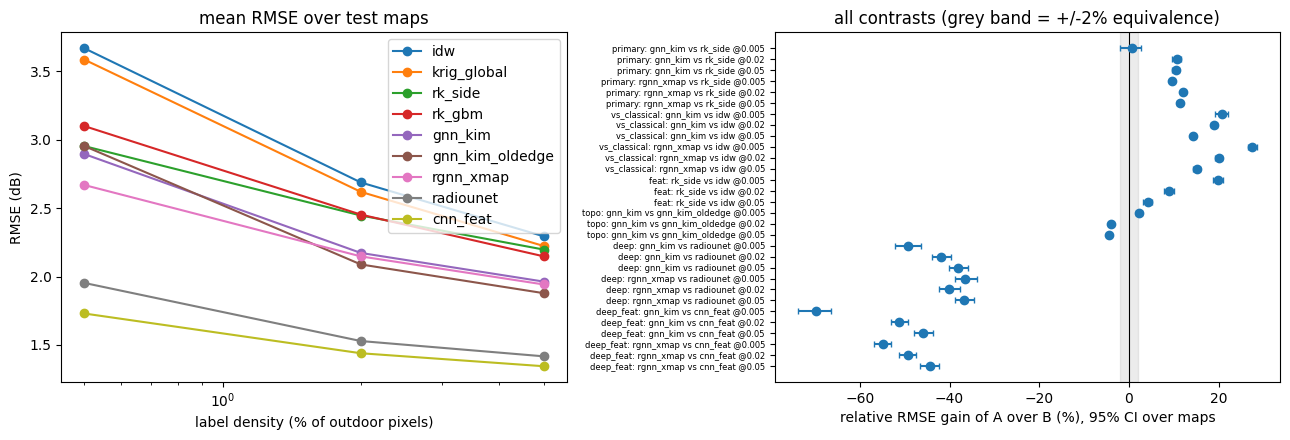


parameters, training time and inference time per learned arm:
                   params  train_s_mean  n_seeds  inference_s_per_map
arm                                                                  
cnn_feat         10932401       1259.32        3                 0.02
gnn_kim             51721       3561.90        3                 0.69
gnn_kim_oldedge     51721       2202.86        3                 0.44
radiounet        10928711       1291.30        3                 0.02
rgnn_xmap           14089       1230.48        3                 0.26

seed spread: std over training seeds of the mean RMSE (dB):
alpha             0.005   0.020   0.050
arm                                    
cnn_feat         0.0078  0.0157  0.0216
gnn_kim          0.0629  0.0732  0.0854
gnn_kim_oldedge  0.0105  0.0126  0.0150
radiounet        0.0312  0.0202  0.0186
rgnn_xmap        0.0158  0.0086  0.0104


In [29]:
def load_results(prefix):
    parts = [R.read_jsonl(OUT / f"{prefix}_classical.jsonl"), R.read_jsonl(OUT / f"{prefix}_learned.jsonl")]
    return pd.concat([p for p in parts if len(p)], ignore_index=True)

def report(df, cfgx, title, label="confirmatory", show_secondary=True):
    print("=" * 100, f"\n{title}\n", "=" * 100)
    U = R.unit_means(df, "rmse")
    t = U.groupby(["arm", "alpha"]).rmse.mean().unstack().reindex(R.ARMS_CLASSICAL + R.ARMS_LEARNED).dropna(how="all")
    print(f"mean test RMSE (dB) over {U['map'].nunique()} maps (maps = units; tx, draws, seeds averaged inside a map)"); print(t.round(3).to_string())
    fam = R.run_families(df, cfgx["alphas"], "rmse", label=label)
    for f, g in fam.groupby("family", sort=False):
        print(f"\n--- family `{f}`  ({len(g)} tests, Holm within family) ---")
        cols = ["A", "B", "alpha", "mean_A", "mean_B", "delta", "gain_pct", "ci_lo", "ci_hi", "p_holm", "verdict"] + (["noninferior"] if "noninferior" in g else [])
        print(g[cols].round(4).to_string(index=False))
    n_better = int(((fam.verdict == "A better") & fam.sig).sum()); n_worse = int(((fam.verdict == "A worse") & fam.sig).sum())
    print(f"\nHolm-significant wins {n_better}, losses {n_worse}, of {len(fam)} tests")
    pos = R.positive_result(fam[fam.family == "primary"])
    print("pre-declared positive GNN result (>= 2 of 3 densities, p_holm < 0.05, gain >= 2%, CI > 0, never significantly worse):")
    print(json.dumps(pos, indent=1))
    if show_secondary:
        sec = df.groupby(["arm", "alpha"])[["mae", "rmse_los", "rmse_nlos", "rmse_edge10", "bacc_q25"]].mean().round(3)
        print("\nsecondary, descriptive (means over rows):"); print(sec.to_string())
        ex = R.run_families(df, cfgx["alphas"], "bacc_q25", kind="diff", label="exploratory: coverage metric, difference in bacc points")
        if len(ex):
            print("\nEXPLORATORY coverage-metric contrasts (delta in balanced-accuracy points; not part of the 30):")
            print(ex[["family", "A", "B", "alpha", "mean_A", "mean_B", "gain_pct", "ci_lo", "ci_hi", "p_holm", "verdict"]].round(3).to_string(index=False))
    return fam, pos, t

def plot_report(fam, t, path):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for arm in t.index:
        ax[0].plot([a * 100 for a in t.columns], t.loc[arm].values, marker="o", label=arm)
    ax[0].set_xlabel("label density (% of outdoor pixels)"); ax[0].set_ylabel("RMSE (dB)"); ax[0].set_xscale("log"); ax[0].legend(); ax[0].set_title("mean RMSE over test maps")
    p = fam.reset_index(drop=True)
    y = np.arange(len(p))[::-1]
    ax[1].errorbar(p.gain_pct, y, xerr=[p.gain_pct - p.ci_lo, p.ci_hi - p.gain_pct], fmt="o", capsize=2)
    ax[1].axvline(0, color="k", lw=.8); ax[1].axvspan(-2, 2, color="grey", alpha=.15)
    ax[1].set_yticks(y); ax[1].set_yticklabels([f"{r.family}: {r.A} vs {r.B} @{r.alpha:g}" for r in p.itertuples()], fontsize=6)
    ax[1].set_xlabel("relative RMSE gain of A over B (%), 95% CI over maps"); ax[1].set_title("all contrasts (grey band = +/-2% equivalence)")
    plt.tight_layout(); plt.savefig(path, dpi=130); plt.show()

if (OUT / "confirm_classical.jsonl").exists():
    df_main = load_results("confirm")
    fam_main, pos_main, tab_main = report(df_main, json.loads(PREREG.read_text())["cfg"] if PREREG.exists() else cfg, "CONFIRMATORY RESULTS (DPM, random split)")
    fam_main.to_csv(OUT / "confirm_contrasts.csv", index=False); tab_main.to_csv(OUT / "confirm_rmse_table.csv")
    plot_report(fam_main, tab_main, OUT / "confirm_summary.png")
    if (OUT / "confirm_models_info.csv").exists():
        mi = pd.read_csv(OUT / "confirm_models_info.csv"); ti = df_main.groupby("arm").t_sec.mean().rename("inference_s_per_map")
        print("\nparameters, training time and inference time per learned arm:")
        print(mi.groupby("arm").agg(params=("params", "first"), train_s_mean=("train_sec", "mean"), n_seeds=("seed", "nunique")).join(ti).round(2).to_string())
        sd = df_main.groupby(["arm", "alpha", "seed", "map"]).rmse.mean().groupby(["arm", "alpha", "seed"]).mean().groupby(["arm", "alpha"]).std().unstack()
        print("\nseed spread: std over training seeds of the mean RMSE (dB):"); print(sd.dropna(how="all").round(4).to_string())
else:
    print("no confirmatory results yet")

## 12. Sensitivity analyses (declared in the plan; reported after the primary tables)
* **Blocked split**: one contiguous 64x64 held-out square is the test region; labels only outside it.
* **IRT2 / IRT4 targets**: models trained on DPM, evaluated against the high-fidelity simulations where the files exist. Models are not retrained.
* **City-cluster bootstrap** (6 clusters, descriptive) if you provide `city_of_map.csv`.
* **Training-transmitters scale check** (exploratory): `gnn_kim`, 1 seed, 2 / 8 / 32 transmitters per training map.

In [30]:
def run_all_arms(cfgx, prereg, split, sim, tag):
    test_maps = prereg["splits"]["test"]
    R.run_classical(cfgx, test_maps, split, sim, OUT / f"{tag}_classical.jsonl")
    for arm in R.ARMS_LEARNED:
        for seed in prereg["seeds"]:
            p = OUT / "models" / f"{arm}_s{seed}.pt"
            if not p.exists():
                print("missing model", p, "-> run section 10 first"); return None
            m, hp, _ = R.load_model(p, arm, cfgx)
            R.run_learned(cfgx, arm, seed, m, hp, test_maps, split, sim, OUT / f"{tag}_learned.jsonl"); del m
    return load_results(tag)

SENS = {}
if (RUN_SENS_BLOCKED or RUN_SENS_IRT) and PREREG.exists() and (OUT / "confirm_classical.jsonl").exists():
    cfgc, prereg, h = frozen_cfg(); R.init(cfgc)
    if RUN_SENS_BLOCKED:
        SENS["blocked"] = run_all_arms(cfgc, prereg, "blocked", cfgc["sim"], "sens_blocked")
    if RUN_SENS_IRT:
        for sim in ("IRT2", "IRT4"):
            n_avail = sum(R._STATE["data"].exists(m, t, sim) for m in prereg["splits"]["test"] for t in R.tx_list(cfgc, m))
            print(f"{sim}: {n_avail} of {len(prereg['splits']['test']) * cfgc['n_tx_test']} test (map, tx) pairs have a file")
            if n_avail >= 10:
                SENS[sim] = run_all_arms(cfgc, prereg, "random", sim, f"sens_{sim.lower()}")
    for k, d in SENS.items():
        if d is not None and len(d):
            report(d, cfgc, f"SENSITIVITY: {k}", label=f"sensitivity:{k}", show_secondary=False)
else:
    print("sensitivity runs not requested, or section 10 not finished")

sensitivity runs not requested, or section 10 not finished


In [31]:
# city-cluster bootstrap (descriptive); needs a map -> city table that is not in the files I could inspect
city_file = next((p for p in [Path("city_of_map.csv"), Path(cfg["data_root"]) / "city_of_map.csv"] if p.exists()), None)
if city_file is not None and (OUT / "confirm_classical.jsonl").exists():
    cm = pd.read_csv(city_file).set_index("map")["city"].to_dict()
    rows = [dict(A=A, B=B, alpha=a, **R.cluster_bootstrap(df_main, cm, A, B, a)) for fam_ in ("primary", "feat") for A, B in R.FAMILIES[fam_]["pairs"] for a in cfg["alphas"]]
    print(pd.DataFrame(rows).round(3).to_string(index=False))
else:
    print("city_of_map.csv not provided (columns: map,city) or no results yet: city-cluster bootstrap skipped")

city_of_map.csv not provided (columns: map,city) or no results yet: city-cluster bootstrap skipped


In [32]:
# exploratory scale check: transmitters per training map (gnn_kim, seed 0)
if RUN_SCALE_CHECK and PREREG.exists() and (OUT / "confirm_classical.jsonl").exists():
    cfgc, prereg, h = frozen_cfg(); R.init(cfgc); ckpt_c = R.make_val_ctxs(cfgc, splits["val"], cfgc["ckpt_val_maps"], "ckpt")
    for ntx in ([2, 8, 32] if not SMOKE else [1, 2, 3]):
        cx = json.loads(json.dumps(cfgc)); cx["n_tx_train"] = ntx
        pool_x = R.make_pool(cx, splits["train"], ntx)
        R.precompute_geometry(cx, splits["train"], lambda m: R.pick_tx(cx, m, ntx, "train"))
        m, hp, info = train_or_load("gnn_kim", 0, cx, prereg["learned_hp"], pool_x, ckpt_c, tag=f"_scaletx{ntx}")
        R.run_learned(cx, "gnn_kim", 0, m, hp, prereg["splits"]["test"], "random", cx["sim"], OUT / f"scale_tx{ntx}_learned.jsonl")
    parts = []
    for ntx in ([2, 8, 32] if not SMOKE else [1, 2, 3]):
        d = R.read_jsonl(OUT / f"scale_tx{ntx}_learned.jsonl"); d["n_tx_train"] = ntx; parts.append(d)
    sc = pd.concat(parts); print("EXPLORATORY: gnn_kim mean RMSE (dB) vs transmitters per training map"); print(sc.groupby(["n_tx_train", "alpha"]).rmse.mean().unstack().round(3).to_string())
else:
    print("scale check not requested")

scale check not requested


In [33]:
KS.push("end of session")

sync: nothing new


## 13. Not implemented / open
* **BRATLab Radiomap-Data replication** (plan: optional): not implemented. I have not inspected that dataset, and the plan says to include it only if it can be split by area without overlap. Add it as a separate plan once you have checked that.
* **Per-map city labels**: need `city_of_map.csv`.
* **Compute**: the plan's budget (30 configurations x 4 learned arms, 3 seeds, 99 test maps x 4 transmitters x 5 draws x 3 densities per arm) is large. Section 4 projects it on your machine; any reduction has to be decided before the freeze.
* **Paper statement**: if the pre-declared positive result is not met, the statement is "no", reported with the same weight as a yes (plan section 2).